# Group 23 · ACDT 2026 · Project 1 · Weeks 5–6 (version 3)
**Temperature regression → temperature-adjusted fare test → is 따릉이 a leisure mode? → can we call it causal?**

* **Question 1** — How strongly does temperature move 따릉이 usage?
  Simple linear regression, daily total rentals on daily mean temperature, all 365 days of 2022 (Week 4 Part A).
* **Question 2** — Did the weekday commuting-hour share rise after each fare rise, once temperature is removed?
  Windows: 7 Oct – 31 Dec (2023 vs 2022) and 1 Jul – 30 Sep (2025 vs 2024).
  Fit share ~ temperature on the pre-rise window, take residuals, two-sided Welch t-test post vs pre
  (Week 3 canvas: a fall would contradict the conventional wisdom as much as a rise), plus TOST equivalence at ±3 pp.
  Checks: the unadjusted Week 3 test and a multiple regression (share ~ post + temperature + rain).
* **Question 3** — Falsification: the same test on leisure-zone stations should show no change.
* **Optional** — double machine learning (partialling-out) version of Question 2.
* **Version 2** — other test families (F, χ², Levene, Mann–Whitney, TOST, power), three tests of the premise
  ("따릉이 is mainly leisure"), and causal checks (difference-in-differences, station fixed effects, permutation placebo,
  parallel-trend and Chow tests).

* **Week 6** — professor's feedback: multiple regression with all controls vs simple regression (section 16),
  and a machine-learning map of what drives usage (section 17).

* **Figures 1–13** — one figure per interpretation; see the figure guide below.

**Run order:** run the setup cell (it finds or asks for Group23_W5_bundle.zip), then Runtime → Run all.
The whole notebook takes well under a minute.

### 0. Setup — run this cell first
Everything the notebook needs is in **Group23_W5_bundle.zip**:

```
data/
  kma_seoul_108_daily.csv      KMA ASOS daily, Seoul (108), 2022-01-01 – 2025-09-30
  daily/                       일별 대여건수, 2022 (two half-year files) → Question 1, premise test P1
  station_day_cache.csv.gz     hourly files condensed to weekday × station (680,258 rows) → Questions 2–3, causal checks
  stations/station_master.xlsx 대여소 정보 (zones are made from station names)
```
* **Colab:** run the cell below and choose the zip when the upload button appears. Then Runtime → Run all.
* **Jupyter on your computer:** unzip the bundle and open this notebook from the unzipped folder.

Figures are saved to `figures/`, result tables to `results/`.

In [1]:
import os, glob, zipfile

def _find_root():
    for c in glob.glob('**/data/station_day_cache.csv.gz', recursive=True):
        return os.path.dirname(os.path.dirname(os.path.abspath(c)))

if os.path.exists('data/station_day_cache.csv.gz'):
    root = os.getcwd()
elif os.path.exists('../data/station_day_cache.csv.gz'):      # notebook inside analysis/ of the GitHub repository
    root = os.path.abspath('..')
else:
    root = _find_root()
if root is None:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Unzip Group23_W5_bundle.zip and open this notebook from the unzipped folder.')
    print('Choose Group23_W5_bundle.zip')
    for name in files.upload():
        if name.lower().endswith('.zip'):
            zipfile.ZipFile(name).extractall('.')
    root = _find_root()
os.chdir(root)
print('working folder:', os.getcwd())
%matplotlib inline

working folder: /tmp/claude-0/-home-claude/893737df-1428-501a-9f55-dd7b14055196/scratchpad/v2/bundle3/Group23_W5_bundle


### Figure guide — one figure per interpretation
| Figure | What we concluded | Where |
|---|---|---|
| 1 `fig1_q1_fit` | Temperature strongly drives daily rentals (β₁ ≈ 3,200 per °C, R² ≈ 0.46), but the residuals form an arch | Question 1 |
| 2 `fig2_q1_rain_and_curve` | The slope is below our 5,000 guess because rain days drag the line down and usage peaks near 24 °C | Question 1 |
| 3 `fig3_volume_vs_share` | Temperature moves *how many* people ride, not *when* → the share is a clean outcome | Q1 → Q2 |
| 4 `fig4_daily_shares` | Daily shares before and after each rise overlap in both zones | Questions 2–3 |
| 5 `fig5_fare_effects` | No significant change after either rise; every interval inside ±3 pp | Questions 2–3 |
| 6 `fig6_dose_response` | Per 1 % of fare rise the response is near zero both times | Question 2 |
| 7 `fig7_robustness` | Same answer with every method and every day-exclusion rule | checks |
| 8 `fig8_leisure_premise` | Fewer rides on weekends (not leisure-led), but commuting-hour rides are as weather-sensitive as the rest (optional mode) | premise |
| 9 `fig9_did_gap` | The commute − leisure gap follows the same path in both years: no jump after the rise | causal |
| 10 `fig10_placebo` | The commute zone changed like any random group of stations | causal |
| 11 `fig11_causal_summary` | Every causal design lands inside ±3 pp | causal |
| 12 `fig12_simple_vs_multiple` | Multiple regression explains 86 % vs 46 %; leaving rain out biases the temperature slope down | feedback |
| 13 `fig13_ml_importance` | A random forest ranks hours of rain above rain amount and the fare rise near zero | Map C |

In [2]:
# ---------- 1. Settings carried from Weeks 3–4 ----------
import math, os, glob, re, warnings
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 150)

COMMUTE = [7, 8, 18, 19]                     # rentals starting 07:00–08:59 and 18:00–19:59
FARE = {"A": 1225, "B": 1450, "C": 1525}     # average of subway and bus base fare (₩)

# Windows (Brandon's rule): about three months from each fare rise, compared with the SAME dates one year
# earlier, so each comparison stays inside one season and never crosses the ~22–25 °C usage peak.
#   2023 rise: subway 7 Oct 2023 (bus 12 Aug 2023)  -> 7 Oct – 31 Dec, 2023 vs 2022
#              (ends before New Year and well before the Climate Card, usable from 27 Jan 2024)
#   2025 rise: subway 28 Jun 2025                    -> 1 Jul – 30 Sep, 2025 vs 2024
#              (28–30 Jun hold one weekday each year; 1 Jul 2024 is when the Climate Card became permanent)
EVENTS = {
    1: {"pre":  ("2022-10-07", "2022-12-31"), "pre_regime":  "A",
        "post": ("2023-10-07", "2023-12-31"), "post_regime": "B", "dose": 18.37},
    2: {"pre":  ("2024-07-01", "2024-09-30"), "pre_regime":  "B",
        "post": ("2025-07-01", "2025-09-30"), "post_regime": "C", "dose": 5.17},
}
# Rail-strike weekdays push commuters onto bikes whatever the fare (Week 4 amendment A1)
STRIKE_DAYS = pd.to_datetime([
    "2022-11-30",                                   # Seoul Metro
    "2023-11-09", "2023-11-10",                     # Seoul Metro, ~82 % service
])
# Public holidays on weekdays inside the windows (no commuting)
HOLIDAYS = pd.to_datetime([
    "2022-10-10",                                   # 한글날 substitute holiday
    "2023-10-09", "2023-12-25",                     # 한글날, 성탄절
    "2024-08-15", "2024-09-16", "2024-09-17", "2024-09-18",   # 광복절, 추석
    "2025-08-15",                                   # 광복절 (추석 2025 falls in October, outside the window)
])
# Bridge days next to 추석 2024 — kept in the main run, dropped in the sensitivity check
BRIDGE_DAYS = pd.to_datetime(["2024-09-13", "2024-09-19", "2024-09-20"])
# College entrance exam days (offices open late) — sensitivity only. 2023's 수능 had a 44 % commute share.
SUNEUNG_DAYS = pd.to_datetime(["2022-11-17", "2023-11-16"])
HEAVY_RAIN_MM = 30          # sensitivity: drop days with this much rain or more (summer storms swing the share both ways)
EXCLUDE = STRIKE_DAYS.append(HOLIDAYS)
ALPHA = 0.05
MEANINGFUL_PP = 3.0                          # Week 2/3 practical threshold
Q1_YEAR = 2022                               # Week 4 Part A: all 365 days of 2022

# Zone rule (Week 3), with point data standing in for exits and entrances
CORE_DISTRICTS = {"종로구", "중구", "강남구", "서초구", "영등포구"}   # CBD, GBD, YBD
SUBWAY_RADIUS = 400    # m from a subway STATION point (exits sit up to ~150 m from it; Week 3 used 300 m from exits)
PARK_RADIUS   = 500    # m from a park POINT (a park's listed point is inside the park, not at an entrance)

In [3]:
# ---------- 2. File locations (edit these) ----------
DATA_DIR     = "data"
HOURLY_GLOB  = os.path.join(DATA_DIR, "hourly", "*.csv")    # 시간대별 이용정보: 2022·2023 Oct–Dec, 2024·2025 Jul–Sep (12 files)
DAILY_GLOB   = os.path.join(DATA_DIR, "daily", "*.csv")     # 일별 대여건수, 2022 (two half-year files)
WEATHER_GLOB = os.path.join(DATA_DIR, "kma*.csv")   # KMA ASOS 일자료, 서울(108), 2022-01-01 – 2025-12-31 (one or several files)
STATION_FILE = os.path.join(DATA_DIR, "stations", "station_master.xlsx")   # 따릉이 대여소 정보 (OA-13252), the .xlsx as downloaded
SUBWAY_FILE  = os.path.join(DATA_DIR, "stations", "subway_stations.csv")   # 서울시 역사마스터 정보
PARK_FILE    = os.path.join(DATA_DIR, "stations", "parks.csv")             # 서울시 주요 공원현황
CACHE        = os.path.join(DATA_DIR, "station_day_cache.csv.gz")   # made by Group23_condense_ttareungi.py or Step 2

In [4]:
# ---------- 3. Robust readers for Korean public-data files ----------
ENCODINGS = ("cp949", "utf-8-sig", "utf-8", "euc-kr")

def _pick(columns, *names, required=True, label=""):
    """First column matching the FIRST name that matches (exact, then substring), case-insensitive."""
    cols = [str(c).strip() for c in columns]
    for n in names:
        for c in cols:
            if n.lower() == c.lower():
                return c
    for n in names:
        for c in cols:
            if n.lower() in c.lower():
                return c
    if required:
        raise KeyError(f"{label}: none of {names} found. Columns are: {cols}")
    return None

def _read_table(path, header_tokens=None, **kw):
    """CSV or Excel, any common Korean encoding. If header_tokens is given, skip title rows above the header."""
    ext = os.path.splitext(path)[1].lower()
    def load(header):
        if ext in (".xlsx", ".xls"):
            return pd.read_excel(path, header=header, **kw)
        last = None
        for enc in ENCODINGS:
            try:
                return pd.read_csv(path, encoding=enc, header=header, low_memory=False, **kw)
            except UnicodeDecodeError as e:
                last = e
        raise RuntimeError(f"Could not decode {path}: {last}")
    if not header_tokens:
        df = load(0)
    else:
        raw = load(None)
        # header = the first of the top rows with the most cells containing a token (title rows score lower)
        scores = [sum(any(t in str(v) for t in header_tokens) for v in raw.iloc[i].values)
                  for i in range(min(15, len(raw)))]
        hit = int(np.argmax(scores)) if scores and max(scores) > 0 else 0
        df = raw.iloc[hit + 1:].reset_index(drop=True)
        df.columns = [str(c).strip() for c in raw.iloc[hit].values]
    df.columns = [str(c).strip() for c in df.columns]
    return df

def _norm_id(s):
    """'00102' and '102' must match; non-numeric IDs such as 'ST-102' are left as they are."""
    s = s.astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
    return s.where(~s.str.fullmatch(r"\d+"), s.str.lstrip("0").replace("", "0"))

def _to_date(s):
    s = s.astype(str).str.strip().str.replace(r"[./]", "-", regex=True)
    s = s.where(~s.str.fullmatch(r"\d{8}"), s.str[:4] + "-" + s.str[4:6] + "-" + s.str[6:8])
    return pd.to_datetime(s.str[:10], errors="coerce")

def _to_num(s):
    return pd.to_numeric(s.astype(str).str.replace(",", "").str.strip(), errors="coerce")

def _check_wgs84(lat, lon, label):
    ok = lat.between(33, 39).mean() > 0.95 and lon.between(124, 132).mean() > 0.95
    if not ok:
        raise ValueError(
            f"{label}: coordinates are not latitude/longitude (sample lat={lat.iloc[0]}, lon={lon.iloc[0]}). "
            "If the file has both TM and WGS84 columns, keep the WGS84 ones; otherwise convert, e.g.\n"
            "  from pyproj import Transformer\n"
            "  lon, lat = Transformer.from_crs('EPSG:5186', 'EPSG:4326', always_xy=True).transform(x, y)")

LAT_NAMES = ("위도", "lat", "latitude", "y좌표(wgs84)", "y좌표", "Y")
LON_NAMES = ("경도", "lon", "longitude", "lng", "x좌표(wgs84)", "x좌표", "X")

In [5]:
# ---------- 4. 따릉이 files ----------
def _read_hourly(path):
    """One monthly 시간대별 이용정보 file -> date, station, total, commute (weekdays only)."""
    head = _read_table(path, nrows=5)
    cols = list(head.columns)
    if any("대여년월" in c for c in cols) and not any(k in c for c in cols for k in ("대여일자", "대여일시", "대여시간")):
        raise ValueError(f"{os.path.basename(path)} is the MONTHLY dataset (대여년월, no date or hour). "
                         "Download '서울시 공공자전거 이용정보(시간대별)' (OA-15245) instead.")
    c = {"date": _pick(cols, "대여일자", "대여일시", "date", label=path),
         "hour": _pick(cols, "대여시간", "시간대", "hour", required=False),
         "station": _pick(cols, "대여소번호", "대여소 번호", "station", label=path),
         "n": _pick(cols, "이용건수", "대여건수", "count", label=path)}
    df = _read_table(path, usecols=[v for v in c.values() if v is not None])
    raw_date = df[c["date"]].astype(str).str.strip()
    out = pd.DataFrame({"date": _to_date(raw_date),
                        "hour": (_to_num(df[c["hour"]]) if c["hour"] else pd.to_datetime(raw_date, errors="coerce").dt.hour),
                        "station": _norm_id(df[c["station"]]), "n": _to_num(df[c["n"]]).fillna(0)})
    out = out[out["date"].dt.weekday < 5]
    out["commute"] = np.where(out["hour"].isin(COMMUTE), out["n"], 0)
    return out.groupby(["date", "station"], as_index=False)[["n", "commute"]].sum()

def load_station_day():
    """Weekday (station, date) totals and commuting-hour rentals. Built once, then read from CACHE."""
    for c in (CACHE, "station_day_cache.csv.gz", "station_day_cache.csv"):
        if os.path.exists(c):
            sd = pd.read_csv(c, parse_dates=["date"], dtype={"station": str})
            sd["station"] = _norm_id(sd["station"])
            print(f"cache: {len(sd):,} station-days from {c}")
            return sd
    paths = sorted(glob.glob(HOURLY_GLOB))
    if not paths:
        raise FileNotFoundError(f"No hourly files match {HOURLY_GLOB}")
    parts = []
    for p in paths:
        g = _read_hourly(p)
        parts.append(g)
        print(f"  read {os.path.basename(p):40s} -> {len(g):>7,} station-days, "
              f"{g.date.min():%Y-%m-%d} – {g.date.max():%Y-%m-%d}")
    sd = pd.concat(parts).groupby(["date", "station"], as_index=False)[["n", "commute"]].sum()
    sd = sd.rename(columns={"n": "total"})
    sd.to_csv(CACHE, index=False, compression="gzip")
    return sd

def load_daily_totals():
    """일별 대여건수 files -> one row per date with the city-wide total (all days, weekends included)."""
    paths = sorted(glob.glob(DAILY_GLOB))
    if not paths:
        raise FileNotFoundError(f"No daily files match {DAILY_GLOB}")
    parts = []
    for p in paths:
        raw = _read_table(p, header_tokens=("대여일자", "대여일시", "일자", "일시", "날짜"))
        d = pd.DataFrame({"date": _to_date(raw[_pick(raw.columns, "대여일자", "대여일시", "일자", "일시", "날짜", "date", label=p)]),
                          "rentals": _to_num(raw[_pick(raw.columns, "대여건수", "이용건수", "건수", "count", label=p)])})
        parts.append(d.dropna())
    daily = pd.concat(parts).groupby("date", as_index=False)["rentals"].sum()   # sums over stations if present
    print(f"daily totals: {len(daily):,} days, {daily.date.min():%Y-%m-%d} – {daily.date.max():%Y-%m-%d}")
    return daily

In [6]:
# ---------- 5. Weather (KMA ASOS Seoul 108, daily) ----------
def load_weather(pattern=WEATHER_GLOB):
    paths = sorted(glob.glob(pattern))
    if not paths:
        raise FileNotFoundError(f"No KMA file matches {pattern}")
    parts = []
    for path in paths:                      # one file, or one per year if the portal limits the period
        w = _read_table(path, header_tokens=("일시", "평균기온"))
        L = f"weather ({os.path.basename(path)})"
        stn = _pick(w.columns, "지점", required=False)
        if stn is not None and w[stn].astype(str).str.contains("108").any():
            w = w[w[stn].astype(str).str.contains("108")]   # keep Seoul (108) if several stations were downloaded
        parts.append(pd.DataFrame({
            "date":   _to_date(w[_pick(w.columns, "일시", "date", label=L)]),
            "temp":   _to_num(w[_pick(w.columns, "평균기온", "temp", label=L)]),
            "precip": _to_num(w[_pick(w.columns, "일강수량", "precip", label=L)]).fillna(0.0),   # blank = no rain
        }))
    out = pd.concat(parts).dropna(subset=["date", "temp"]).drop_duplicates("date").sort_values("date")
    print(f"weather: {len(out):,} days, {out.date.min():%Y-%m-%d} – {out.date.max():%Y-%m-%d}, "
          f"mean {out.temp.mean():.1f} °C")
    return out

In [7]:
# ---------- 6. Zones (Week 3 rule; station and park points stand in for exits and entrances) ----------
def _haversine(lat1, lon1, lat2, lon2):
    R = 6_371_000.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

def _nearest(lat, lon, plat, plon, chunk=500):
    out = np.empty(len(lat))
    for i in range(0, len(lat), chunk):
        d = _haversine(lat[i:i+chunk, None], lon[i:i+chunk, None], plat[None, :], plon[None, :])
        out[i:i+chunk] = d.min(axis=1)
    return out

def load_points(path, label):
    raw = _read_table(path, header_tokens=("위도", "경도", "WGS", "좌표", "lat"))
    pts = pd.DataFrame({"lat": _to_num(raw[_pick(raw.columns, *LAT_NAMES, label=label)]),
                        "lon": _to_num(raw[_pick(raw.columns, *LON_NAMES, label=label)])}).dropna()
    _check_wgs84(pts.lat, pts.lon, label)
    print(f"{label}: {len(pts):,} points")
    return pts

def load_stations(path=STATION_FILE):
    """따릉이 대여소 정보 (.xlsx with a 4-row header, or a simple CSV) -> station, name, district, lat, lon."""
    if path.lower().endswith((".xlsx", ".xls")):
        raw = pd.read_excel(path, header=None)
    else:
        raw = _read_table(path, header_tokens=None)
        raw = pd.concat([raw.columns.to_frame().T, raw], ignore_index=True)
        raw.columns = range(raw.shape[1])
    # the first data row is the first row whose first cell is a number and that holds a Seoul latitude
    num = raw.apply(lambda c: pd.to_numeric(c, errors="coerce"))
    lat_col = int(num.apply(lambda c: c.between(33, 39).mean()).idxmax())
    lon_col = int(num.apply(lambda c: c.between(124, 132).mean()).idxmax())
    first = int(np.argmax(num[0].notna() & num[lat_col].between(33, 39)))
    hdr = [" ".join(str(v).replace("\n", "") for v in raw.iloc[:first, j] if pd.notna(v)) for j in range(raw.shape[1])]
    body = raw.iloc[first:].reset_index(drop=True)
    name_col = next((j for j, h in enumerate(hdr) if "명" in h), 1)
    dist_col = next((j for j, h in enumerate(hdr) if "자치구" in h), None)
    st = pd.DataFrame({"station": _norm_id(body[0]), "name": body[name_col].astype(str).str.strip(),
                       "lat": _to_num(body[lat_col]), "lon": _to_num(body[lon_col])})
    if dist_col is not None:
        st["district"] = body[dist_col].astype(str).str.strip()
    else:
        addr = next(j for j, h in enumerate(hdr) if "주소" in h)
        st["district"] = body[addr].astype(str).str.extract(r"(\S+구)")[0]
    st = st[st.station.str.fullmatch(r"\d+") & st.lat.between(33, 39)]
    print(f"station master: {len(st):,} stations, {st.district.nunique()} districts")
    return st

# Zone rule by station NAME (used when subway/park coordinate files are not available — Seoul's 역사마스터 has no file):
#   C = in a core business district AND the station is named after a subway exit ("○○역 N번출구")
#   L = named after a park ("공원"), excluding children's playgrounds, small parks and subway names,
#       plus Han River access points (한강공원, 나들목, 선착장, 유원지)
#   a station meeting both, or neither -> U
PARK_EXCLUDE = "어린이|소공원|공원역|출구"
RIVER_WORDS = "한강공원|나들목|선착장|유원지"

def classify_zones_by_name(s):
    exit_named = s["name"].str.contains("출구")
    parkish = ((s["name"].str.contains("공원") & ~s["name"].str.contains(PARK_EXCLUDE))
               | s["name"].str.contains(RIVER_WORDS))
    is_c = s["district"].isin(CORE_DISTRICTS) & exit_named
    s = s.copy()
    s["zone"] = np.select([is_c & ~parkish, parkish & ~is_c], ["C", "L"], default="U")
    print(s["zone"].value_counts().to_string())
    return s

def classify_zones():
    """C = core district AND near a subway station; L = near a park; both or neither -> U.
    Without the subway/park point files, falls back to the station-name rule above."""
    if not os.path.exists(STATION_FILE):
        print(f"station master missing ({STATION_FILE}); analysis runs city-wide only")
        return None
    s = load_stations()
    if not (os.path.exists(SUBWAY_FILE) and os.path.exists(PARK_FILE)):
        print("subway/park point files not found → zones from station names")
        return classify_zones_by_name(s)
    sub = load_points(SUBWAY_FILE, "subway stations")
    park = load_points(PARK_FILE, "parks")
    s["d_subway"] = _nearest(s.lat.values, s.lon.values, sub.lat.values, sub.lon.values)
    s["d_park"] = _nearest(s.lat.values, s.lon.values, park.lat.values, park.lon.values)
    is_c = s["district"].isin(CORE_DISTRICTS) & (s["d_subway"] <= SUBWAY_RADIUS)
    is_l = s["d_park"] <= PARK_RADIUS
    s["zone"] = np.select([is_c & ~is_l, is_l & ~is_c], ["C", "L"], default="U")
    print(s["zone"].value_counts().to_string())
    return s

def check_match(sd, zones):
    rate = sd.loc[sd.station.isin(set(zones.station)), "total"].sum() / sd["total"].sum()
    print(f"rentals matched to a classified station: {rate:.1%}")
    if rate < 0.9:
        print(f"  WARNING: usage IDs look like {list(sd.station.unique()[:5])}, "
              f"master IDs like {list(zones.station.unique()[:5])} — check the station-number column")
    return rate

In [8]:
# ---------- 7. Daily share per zone and window ----------
def zone_daily(sd, zones, window, zone, weather, exclude=EXCLUDE):
    """Weekday commuting-hour share for one zone (or 'ALL'), joined to that day's weather."""
    a, b = map(pd.Timestamp, window)
    w = sd[(sd.date >= a) & (sd.date <= b)]
    if zone != "ALL":
        w = w[w.station.isin(set(zones.loc[zones.zone == zone, "station"]))]
    if exclude is not None and len(exclude):
        w = w[~w.date.isin(exclude)]
    g = w.groupby("date", as_index=False)[["total", "commute"]].sum()
    g["share"] = 100 * g.commute / g.total
    return g.merge(weather, on="date", how="left")

In [9]:
# ---------- 8. Test helpers ----------
def lag1(x):
    x = np.asarray(x, float) - np.mean(x)
    return float(np.sum(x[1:] * x[:-1]) / np.sum(x * x))

def welch_greater(pre, post):
    """One-sided Welch t-test (H1: post > pre) with a two-sided 95 % CI for the difference."""
    x, y = np.asarray(pre, float), np.asarray(post, float)
    v1, v2, n1, n2 = x.var(ddof=1), y.var(ddof=1), len(x), len(y)
    se = math.sqrt(v1 / n1 + v2 / n2)
    df = (v1 / n1 + v2 / n2) ** 2 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))
    t, p = stats.ttest_ind(y, x, equal_var=False, alternative="greater")
    diff, tc = y.mean() - x.mean(), stats.t.ppf(0.975, df)
    p_two = float(stats.ttest_ind(y, x, equal_var=False).pvalue)
    return {"n_pre": n1, "n_post": n2, "diff": diff, "t": float(t), "df": df, "p_one": float(p), "p_two": p_two,
            "ci_lo": diff - tc * se, "ci_hi": diff + tc * se, "lag1": max(abs(lag1(x)), abs(lag1(y)))}

def block_bootstrap_ci(x, y, block=5, B=5000, seed=23):
    """Moving-block bootstrap CI for mean(y) − mean(x); used when |lag-1 r| > 0.3 (Week 3 backup)."""
    rng = np.random.default_rng(seed)
    def draw(a):
        k = math.ceil(len(a) / block)
        starts = rng.integers(0, len(a) - block + 1, size=k)
        return np.concatenate([a[s:s + block] for s in starts])[:len(a)]
    x, y = np.asarray(x, float), np.asarray(y, float)
    d = np.array([draw(y).mean() - draw(x).mean() for _ in range(B)])
    return tuple(np.percentile(d, [2.5, 97.5]))

In [10]:
# ---------- 9. Question 1: daily rentals = β0 + β1 · temperature ----------
def temperature_regression(daily, weather, year=Q1_YEAR):
    d = daily.merge(weather, on="date", how="inner")
    d = d[d.date.dt.year == year].sort_values("date").reset_index(drop=True)
    r = stats.pearsonr(d.temp, d.rentals)
    f = stats.linregress(d.temp, d.rentals)
    n, tc = len(d), stats.t.ppf(0.975, len(d) - 2)
    d["fitted"] = f.intercept + f.slope * d.temp
    d["resid"] = d.rentals - d.fitted
    out = {"n": n, "r": r.statistic, "b0": f.intercept, "b1": f.slope, "se_b1": f.stderr,
           "b1_lo": f.slope - tc * f.stderr, "b1_hi": f.slope + tc * f.stderr,
           "r2": f.rvalue ** 2, "p_two": f.pvalue, "resid_lag1": lag1(d.resid)}
    # curvature check: does a squared term help? (diagnostic only — the reported model stays linear)
    q = np.polyfit(d.temp, d.rentals, 2)
    out["r2_quadratic"] = 1 - np.sum((d.rentals - np.polyval(q, d.temp)) ** 2) / np.sum((d.rentals - d.rentals.mean()) ** 2)
    out["peak_temp_quadratic"] = -q[1] / (2 * q[0]) if q[0] < 0 else np.nan

    print(f"Question 1 · {year}, n = {n} days")
    print(f"  r = {out['r']:.3f}   (β1 = r · s_y / s_x)")
    print(f"  β0 = {out['b0']:,.0f} rentals at 0 °C")
    print(f"  β1 = {out['b1']:,.0f} rentals per °C   95% CI [{out['b1_lo']:,.0f}, {out['b1_hi']:,.0f}]")
    print(f"  R² = {out['r2']:.3f}   two-sided p = {out['p_two']:.3g}")
    print(f"  residual lag-1 r = {out['resid_lag1']:.2f}  "
          f"({'p-value too optimistic: days are dependent' if abs(out['resid_lag1']) > 0.3 else 'acceptable'})")
    print(f"  curvature check: R² with a squared term = {out['r2_quadratic']:.3f}"
          + (f", peak near {out['peak_temp_quadratic']:.1f} °C" if not np.isnan(out['peak_temp_quadratic']) else ""))
    bins = pd.qcut(d.temp, 5)
    print("  mean residual by temperature fifth (a U or ∩ pattern means the line misses a curve):")
    print(d.groupby(bins, observed=True)["resid"].mean().round(0).to_string())
    return out, d

In [11]:
# ---------- 10. Question 2/3: temperature-adjusted fare test ----------
def adjusted_fare_test(sd, zones, weather, event, zone, exclude=EXCLUDE):
    spec = EVENTS[event]
    pre = zone_daily(sd, zones, spec["pre"], zone, weather, exclude).dropna(subset=["temp"])
    post = zone_daily(sd, zones, spec["post"], zone, weather, exclude).dropna(subset=["temp"])
    raw = welch_greater(pre.share, post.share)                       # Week 3 test, unadjusted

    fit = stats.linregress(pre.temp, pre.share)                       # share ~ temperature, pre-rise window only
    pre_res = pre.share - (fit.intercept + fit.slope * pre.temp)
    post_res = post.share - (fit.intercept + fit.slope * post.temp)
    adj = welch_greater(pre_res, post_res)

    xbar = pre.share.mean()
    row = {"event": event, "zone": zone, "dose_%": spec["dose"],
           "n_pre": raw["n_pre"], "n_post": raw["n_post"],
           "share_pre": xbar, "share_post": post.share.mean(),
           "temp_pre": pre.temp.mean(), "temp_post": post.temp.mean(),
           "slope_pp_per_C": fit.slope, "slope_p": fit.pvalue, "slope_r2": fit.rvalue ** 2,
           "raw_diff": raw["diff"], "raw_p": raw["p_one"], "raw_lo": raw["ci_lo"], "raw_hi": raw["ci_hi"],
           "adj_diff": adj["diff"], "adj_t": adj["t"], "adj_p": adj["p_one"], "adj_p_two": adj["p_two"],
           "adj_lo": adj["ci_lo"], "adj_hi": adj["ci_hi"], "lag1": adj["lag1"]}
    row["temp_correction"] = fit.slope * (row["temp_post"] - row["temp_pre"])   # part of raw_diff due to temperature
    # Brandon's extrapolation check: the line is fitted on the pre window, so post-window temperatures
    # outside the pre-window range are predictions beyond the data
    row["post_outside_temp_range_%"] = 100 * ((post.temp < pre.temp.min()) | (post.temp > pre.temp.max())).mean()
    to_e = lambda v: (100 * v / xbar) / spec["dose"]
    row["elasticity"], row["elas_lo"], row["elas_hi"] = to_e(adj["diff"]), to_e(adj["ci_lo"]), to_e(adj["ci_hi"])
    row["degree_equivalent"] = adj["diff"] / abs(fit.slope) if abs(fit.slope) > 1e-9 else np.nan
    row["boot_lo"], row["boot_hi"] = (block_bootstrap_ci(pre_res.values, post_res.values)
                                      if adj["lag1"] > 0.3 else (np.nan, np.nan))
    return row

def decision(r):
    """Week 3 rule, two-sided: a fall would contradict the conventional wisdom as much as a rise."""
    if r["adj_p_two"] < ALPHA and (r["adj_lo"] >= MEANINGFUL_PP or r["adj_hi"] <= -MEANINGFUL_PP):
        return "reject H0; CI beyond ±3 pp → meaningful change"
    if r["adj_p_two"] < ALPHA:
        return "reject H0; real but possibly below 3 pp"
    if r["adj_hi"] < MEANINGFUL_PP and r["adj_lo"] > -MEANINGFUL_PP:
        return "fail to reject; CI inside ±3 pp → supports the conventional wisdom"
    return "fail to reject; CI too wide to rule out 3 pp → inconclusive"

def run_fare_tests(sd, zones, weather, exclude=EXCLUDE):
    zlist = ("C", "L") if zones is not None else ("ALL",)
    res = pd.DataFrame([adjusted_fare_test(sd, zones, weather, ev, z, exclude) for ev in EVENTS for z in zlist])
    res["decision"] = res.apply(decision, axis=1)
    show = res[["event", "zone", "n_pre", "n_post", "temp_pre", "temp_post", "slope_pp_per_C",
                "raw_diff", "raw_p", "temp_correction", "adj_diff", "adj_lo", "adj_hi", "adj_p", "adj_p_two",
                "elasticity", "degree_equivalent", "lag1", "post_outside_temp_range_%"]].round(3)
    print(show.to_string(index=False))
    print()
    for _, r in res.iterrows():
        print(f"Event {r.event} · zone {r.zone}: {r.decision}")
        if r["post_outside_temp_range_%"] > 10:
            print(f"   {r['post_outside_temp_range_%']:.0f} % of post-window days lie outside the pre-window "
                  "temperature range → the adjustment extrapolates; compare with the multiple regression")
        if not np.isnan(r.boot_lo):
            print(f"   |lag-1| > 0.3 → moving-block bootstrap CI [{r.boot_lo:.2f}, {r.boot_hi:.2f}]")
    if zones is not None:
        print()
        for ev in EVENTS:
            c, l = (res[(res.event == ev) & (res.zone == z)].iloc[0] for z in ("C", "L"))
            pattern = ("C changes, L does not → supports H1" if c.adj_p_two < ALPHA and l.adj_p_two >= ALPHA else
                       "both change → citywide factor, not the fare" if c.adj_p_two < ALPHA else
                       "L changes, C does not → mechanism contradicted" if l.adj_p_two < ALPHA else
                       "neither moves → conventional wisdom holds for this event")
            print(f"Event {ev} falsification pattern: {pattern}")
    return res

def dose_response(res, zone="C"):
    a = res[(res.zone == zone) & (res.event == 1)].iloc[0]
    b = res[(res.zone == zone) & (res.event == 2)].iloc[0]
    overlap = max(a.elas_lo, b.elas_lo) <= min(a.elas_hi, b.elas_hi)
    print(f"elasticity, 2023 rise: {a.elasticity:.3f} [{a.elas_lo:.3f}, {a.elas_hi:.3f}]")
    print(f"elasticity, 2025 rise: {b.elasticity:.3f} [{b.elas_lo:.3f}, {b.elas_hi:.3f}]")
    zero = a.elas_lo <= 0 <= a.elas_hi and b.elas_lo <= 0 <= b.elas_hi
    print(f"intervals overlap: {overlap} → " + (
        "both include 0: no detectable response to either rise, and the two cannot be told apart" if overlap and zero else
        "consistent with a response proportional to the fare rise" if overlap else
        "response not proportional to the fare rise"))
    return overlap

def sensitivity(sd, zones, weather):
    """Adjusted effect in the commute zone under alternative day exclusions."""
    heavy = pd.DatetimeIndex(weather.loc[weather.precip >= HEAVY_RAIN_MM, "date"])
    variants = {"main (strikes + holidays out)": EXCLUDE,
                "also drop Chuseok 2024 bridge days": EXCLUDE.append(BRIDGE_DAYS),
                "also drop Suneung (exam) days": EXCLUDE.append(SUNEUNG_DAYS),
                f"also drop heavy-rain days (≥{HEAVY_RAIN_MM} mm)": EXCLUDE.append(heavy),
                "holidays out, strikes kept": HOLIDAYS}
    z = "C" if zones is not None else "ALL"
    rows = []
    for name, ex in variants.items():
        for ev in EVENTS:
            r = adjusted_fare_test(sd, zones, weather, ev, z, ex)
            rows.append({"variant": name, "event": ev, "zone": z, "n_pre": r["n_pre"], "n_post": r["n_post"],
                         "adj_diff": r["adj_diff"], "adj_lo": r["adj_lo"], "adj_hi": r["adj_hi"], "adj_p": r["adj_p"]})
    out = pd.DataFrame(rows)
    print(out.round(3).to_string(index=False))
    return out

In [12]:
# ---------- 11. Check: multiple regression share ~ post + temperature + rain (TA-approved) ----------
def mlr_check(sd, zones, weather):
    import statsmodels.api as sm
    zlist = ("C", "L") if zones is not None else ("ALL",)
    rows = []
    for ev, spec in EVENTS.items():
        for z in zlist:
            pre = zone_daily(sd, zones, spec["pre"], z, weather).assign(post=0)
            post = zone_daily(sd, zones, spec["post"], z, weather).assign(post=1)
            d = pd.concat([pre, post]).dropna(subset=["temp"]).sort_values("date")
            X = sm.add_constant(d[["post", "temp", "precip"]].astype(float))
            fit = sm.OLS(d["share"].astype(float), X).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
            b, se = fit.params["post"], fit.bse["post"]
            rows.append({"event": ev, "zone": z, "n": int(fit.nobs), "post_coef": b, "se_HAC": se,
                         "lo": b - 1.96 * se, "hi": b + 1.96 * se,
                         "p_one": float(stats.norm.sf(b / se)), "p_two": float(2 * stats.norm.sf(abs(b / se))),
                         "temp_coef": fit.params["temp"],
                         "rain_coef": fit.params["precip"], "R2": fit.rsquared})
    out = pd.DataFrame(rows)
    print(out.round(3).to_string(index=False))
    return out

In [13]:
# ---------- 12. Optional: double machine learning (partialling-out) ----------
def dml_check(sd, zones, weather, folds=5, seed=23):
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.model_selection import KFold
    zlist = ("C", "L") if zones is not None else ("ALL",)
    rows = []
    for ev, spec in EVENTS.items():
        for z in zlist:
            parts = []
            for period, flag in (("pre", 0), ("post", 1)):
                d = zone_daily(sd, zones, spec[period], z, weather).assign(post=flag)
                d["day_of_window"] = (d.date - pd.Timestamp(spec[period][0])).dt.days
                parts.append(d)
            d = pd.concat(parts).dropna(subset=["temp"]).reset_index(drop=True)
            W = np.column_stack([d.temp, d.precip, d.date.dt.weekday, d.day_of_window])
            Y, D = d.share.values, d.post.values.astype(float)
            rY, rD = np.zeros(len(d)), np.zeros(len(d))
            for tr, te in KFold(folds, shuffle=True, random_state=seed).split(W):
                mY = RandomForestRegressor(300, min_samples_leaf=5, random_state=seed).fit(W[tr], Y[tr])
                mD = RandomForestRegressor(300, min_samples_leaf=5, random_state=seed).fit(W[tr], D[tr])
                rY[te], rD[te] = Y[te] - mY.predict(W[te]), D[te] - mD.predict(W[te])
            theta = np.sum(rY * rD) / np.sum(rD ** 2)
            eps = rY - theta * rD
            se = np.sqrt(np.mean(rD ** 2 * eps ** 2)) / (np.mean(rD ** 2) * np.sqrt(len(d)))
            rows.append({"event": ev, "zone": z, "n": len(d), "theta": theta, "se": se,
                         "lo": theta - 1.96 * se, "hi": theta + 1.96 * se,
                         "p_one": float(stats.norm.sf(theta / se)), "p_two": float(2 * stats.norm.sf(abs(theta / se)))})
    out = pd.DataFrame(rows)
    print(out.round(3).to_string(index=False))
    return out

In [14]:
# ---------- 13. Figures (static; palette slots 1–2 of the validated reference palette) ----------
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834"]

def _style(ax):
    ax.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(GRID)
    ax.tick_params(colors=INK2, labelsize=9)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

def _save(fig, path, top=1.0):
    folder = os.path.dirname(path)
    if folder:
        os.makedirs(folder, exist_ok=True)
    fig.tight_layout(rect=(0, 0, 1, top))
    fig.savefig(path, dpi=150, facecolor=SURFACE, bbox_inches="tight")
    return fig

ZNAME = {"C": "commute zone", "L": "leisure zone", "ALL": "all stations"}
EVENT_NAME = {1: "2023 rise", 2: "2025 rise"}

def plot_q1(d, q1, path="figures/fig1_q1_fit.png"):
    import matplotlib.pyplot as plt
    from matplotlib.ticker import FuncFormatter
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), facecolor=SURFACE)
    ax = axes[0]; _style(ax)
    ax.scatter(d.temp, d.rentals, s=14, color=SERIES[0], alpha=.55, linewidths=0)
    xs = np.linspace(d.temp.min(), d.temp.max(), 50)
    ax.plot(xs, q1["b0"] + q1["b1"] * xs, color=INK, linewidth=2)
    ax.set_xlabel("daily mean temperature (°C)", color=INK2)
    ax.set_ylabel("daily bike rentals (city-wide)", color=INK2)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_title(f"β₁ = {q1['b1']:,.0f} rentals per °C · R² = {q1['r2']:.2f} · n = {q1['n']}",
                 fontsize=10, color=INK, loc="left")
    ax = axes[1]; _style(ax)
    ax.scatter(d.temp, d.resid, s=14, color=SERIES[0], alpha=.55, linewidths=0)
    ax.axhline(0, color=INK2, linewidth=1)
    ax.set_xlabel("daily mean temperature (°C)", color=INK2)
    ax.set_ylabel("residual (rentals)", color=INK2)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_title("Residuals: an arch means the true pattern is curved", fontsize=10, color=INK, loc="left")
    return _save(fig, path)

def plot_q2(res, path="figures/fig5_fare_effects.png"):
    """Point + 95 % CI per event and zone: unadjusted (Week 3) vs temperature-adjusted."""
    import matplotlib.pyplot as plt
    labels = [f"{EVENT_NAME[r.event]} · {ZNAME.get(r.zone, r.zone)}" for _, r in res.iterrows()]
    y = np.arange(len(res))[::-1]
    fig, ax = plt.subplots(figsize=(7.5, 0.6 + 0.55 * len(res)), facecolor=SURFACE)
    _style(ax); ax.grid(axis="y", visible=False)
    for k, (col, lo, hi, name) in enumerate((("raw_diff", "raw_lo", "raw_hi", "unadjusted (Week 3)"),
                                             ("adj_diff", "adj_lo", "adj_hi", "temperature-adjusted"))):
        yy = y + (0.14 if k == 0 else -0.14)
        ax.errorbar(res[col], yy, xerr=[res[col] - res[lo], res[hi] - res[col]], fmt="o", ms=7,
                    color=SERIES[k], ecolor=SERIES[k], elinewidth=2, capsize=0, label=name)
    ax.axvline(0, color=INK2, linewidth=1)
    for v in (-MEANINGFUL_PP, MEANINGFUL_PP):
        ax.axvline(v, color=INK2, linewidth=1, linestyle=(0, (3, 3)))
        ax.text(v, y.max() + 0.5, f" {v:+.0f} pp", color=INK2, fontsize=8, va="bottom")
    ax.set_yticks(y, labels, color=INK)
    ax.set_xlabel("change in commuting-hour share after the fare rise (pp), 95 % CI", color=INK2)
    ax.legend(frameon=False, fontsize=8, loc="lower right", labelcolor=INK)
    ax.set_title("No significant change after either rise, and every interval stays inside ±3 pp",
                 fontsize=10, color=INK, loc="left", pad=18)
    return _save(fig, path)

# ---- Figures for each interpretation (one claim per figure; the title states the claim) ----
RAIN_DAY_MM = 1.0     # a "rain day" for Figure 2: at least 1 mm of rain

def plot_q1_why(d, q1, path="figures/fig2_q1_rain_and_curve.png"):
    """Interpretation: β1 is below our 5,000 guess because rain days drag the line down and the pattern is curved."""
    import matplotlib.pyplot as plt
    from matplotlib.ticker import FuncFormatter
    wet = d.precip >= RAIN_DAY_MM
    dry = d[~wet]
    fd = stats.linregress(dry.temp, dry.rentals)
    xs = np.linspace(d.temp.min(), d.temp.max(), 100)
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), facecolor=SURFACE, sharey=True)

    ax = axes[0]; _style(ax)
    ax.scatter(dry.temp, dry.rentals, s=14, color=SERIES[0], alpha=.5, linewidths=0,
               label=f"dry day (< {RAIN_DAY_MM:g} mm), n = {len(dry)}")
    ax.scatter(d.temp[wet], d.rentals[wet], s=16, color=SERIES[1], alpha=.8, linewidths=0,
               label=f"rain day (≥ {RAIN_DAY_MM:g} mm), n = {int(wet.sum())}")
    ax.plot(xs, q1["b0"] + q1["b1"] * xs, color=INK, linewidth=2,
            label=f"all days: β₁ = {q1['b1']:,.0f}, R² = {q1['r2']:.2f}")
    ax.plot(xs, fd.intercept + fd.slope * xs, color=SERIES[0], linewidth=2, linestyle=(0, (5, 2)),
            label=f"dry days only: β₁ = {fd.slope:,.0f}, R² = {fd.rvalue ** 2:.2f}")
    ax.set_title("Rain days fall far below the line and flatten it", fontsize=10, color=INK, loc="left")
    ax.legend(frameon=False, fontsize=8, loc="upper left", labelcolor=INK)

    ax = axes[1]; _style(ax)
    ax.scatter(dry.temp, dry.rentals, s=12, color=SERIES[0], alpha=.18, linewidths=0)
    ax.scatter(d.temp[wet], d.rentals[wet], s=12, color=SERIES[1], alpha=.3, linewidths=0)
    for sub, col, name in ((d, INK, "all days"), (dry, SERIES[0], "dry days only")):
        q = np.polyfit(sub.temp, sub.rentals, 2)
        peak = -q[1] / (2 * q[0])
        ax.plot(xs, np.polyval(q, xs), color=col, linewidth=2, label=f"{name}: peak ≈ {peak:.1f} °C")
        ax.axvline(peak, color=col, linewidth=1, linestyle=":")
    hot = d.temp > 24
    ax.set_title(f"Usage peaks near 24 °C, or 27 °C on dry days: part of the hot-day drop\n"
                 f"is rain ({100 * (d.precip[hot] >= RAIN_DAY_MM).mean():.0f} % of days above 24 °C had rain, "
                 f"{100 * (d.precip[~hot] >= RAIN_DAY_MM).mean():.0f} % of cooler days)",
                 fontsize=10, color=INK, loc="left")
    ax.legend(frameon=False, fontsize=8, loc="upper left", labelcolor=INK)
    for ax in axes:
        ax.set_xlabel("daily mean temperature (°C)", color=INK2)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    axes[0].set_ylim(-8000, 1.33 * d.rentals.max())      # headroom for the legends; the curve's dip below 0 is cut
    axes[0].set_ylabel("daily bike rentals (city-wide, 2022)", color=INK2)
    fig.suptitle("Question 1 · why the slope is below our 5,000-per-°C guess", x=0.01, ha="left",
                 fontsize=11, color=INK, fontweight="bold")
    return _save(fig, path)

def _window_days(sd, weather, zone="ALL", zones=None):
    rows = []
    for ev, spec in EVENTS.items():
        for per in ("pre", "post"):
            g = zone_daily(sd, zones, spec[per], zone, weather).dropna(subset=["temp"])
            g["event"], g["period"] = ev, per
            rows.append(g)
    return pd.concat(rows, ignore_index=True)

def plot_volume_vs_share(sd, weather, path="figures/fig3_volume_vs_share.png"):
    """Interpretation: temperature moves HOW MANY people ride, not WHEN they ride → the share is a clean outcome."""
    import matplotlib.pyplot as plt
    a = _window_days(sd, weather)
    season = {1: "Oct–Dec windows (2023 rise)", 2: "Jul–Sep windows (2025 rise)"}
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), facecolor=SURFACE, sharey=True)
    for ax, col, title, unit in ((axes[0], "total", "Daily rentals", "rentals"),
                                 (axes[1], "share", "Commuting-hour share (07–09 h + 18–20 h)", "pp")):
        _style(ax)
        for k, (ev, g) in enumerate(a.groupby("event")):
            y = 100 * g[col] / g[col].mean()               # each measure as % of its own season average
            f, fy = stats.linregress(g.temp, g[col]), stats.linregress(g.temp, y)
            xs = np.linspace(g.temp.min(), g.temp.max(), 20)
            slope = f"{f.slope:+,.0f} rentals" if unit == "rentals" else f"{f.slope:+.3f} pp"
            ax.scatter(g.temp, y, s=14, color=SERIES[k], alpha=.5, linewidths=0)
            ax.plot(xs, fy.intercept + fy.slope * xs, color=SERIES[k], linewidth=2,
                    label=f"{season[ev]}: {slope} per °C, R² = {f.rvalue ** 2:.2f}")
        ax.axhline(100, color=INK2, linewidth=1)
        ax.set_title(title, fontsize=10, color=INK, loc="left")
        ax.set_xlabel("daily mean temperature (°C)", color=INK2)
        ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.16), labelcolor=INK)
    axes[0].set_ylabel("% of the season's average (weekdays)", color=INK2)
    fig.suptitle("Temperature moves how many people ride (in autumn), but not when they ride (in either season)",
                 x=0.01, ha="left",
                 fontsize=11, color=INK, fontweight="bold")
    return _save(fig, path)

def plot_daily_shares(sd, zones, weather, res, path="figures/fig4_daily_shares.png"):
    """Interpretation: the before/after clouds of daily shares overlap in both zones; zone levels are close."""
    import matplotlib.pyplot as plt
    zlist = ("C", "L") if zones is not None else ("ALL",)
    rng = np.random.default_rng(23)
    data = {(ev, z): _window_days(sd, weather, z, zones).query("event == @ev") for ev in EVENTS for z in zlist}
    top = max(g.share.max() for g in data.values())
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), facecolor=SURFACE, sharey=True)
    for ax, (ev, spec) in zip(axes, EVENTS.items()):
        _style(ax); ax.grid(axis="x", visible=False)
        ticks, labels = [], []
        for i, z in enumerate(zlist):
            g = data[(ev, z)]
            for j, per in enumerate(("pre", "post")):
                v = g.loc[g.period == per, "share"]
                x = i * 2.6 + j
                ax.scatter(x + rng.uniform(-.27, .27, len(v)), v, s=12, color=SERIES[j], alpha=.55, linewidths=0)
                ax.hlines(v.mean(), x - .34, x + .34, color=INK, linewidth=2.2)
                ax.text(x + .37, v.mean(), f"{v.mean():.1f}", va="center", fontsize=8, color=INK)
                ticks.append(x); labels.append(f"{'before' if per == 'pre' else 'after'}\n{spec[per][0][:4]}")
            r = res[(res.event == ev) & (res.zone == z)].iloc[0]
            ax.text(i * 2.6 + .5, top + 1.2, f"{ZNAME[z]}\nadjusted Δ {r.adj_diff:+.2f} pp · p = {r.adj_p_two:.2f}",
                    ha="center", va="bottom", fontsize=8.5, color=INK)
        ax.set_xticks(ticks, labels, color=INK2, fontsize=8)
        ax.set_ylim(None, top + 5)
        months = "Oct–Dec" if ev == 1 else "Jul–Sep"
        ax.set_title(f"{EVENT_NAME[ev]} ({months} weekdays)", fontsize=10, color=INK, loc="left")
    axes[0].set_ylabel("daily commuting-hour share (%)", color=INK2)
    fig.suptitle("The daily shares before and after each rise overlap heavily, in both zones",
                 x=0.01, ha="left", fontsize=11, color=INK, fontweight="bold")
    if zones is not None:
        gaps = [data[(ev, "C")].share.mean() - data[(ev, "L")].share.mean() for ev in EVENTS]
        fig.text(0.01, 0.935, f"Black bars = means; blue = before, orange = after. The commute zone sits only "
                 f"{min(gaps):.1f}–{max(gaps):.1f} pp above the leisure zone.", ha="left", va="top", fontsize=9, color=INK2)
    return _save(fig, path, top=0.9)

def plot_dose_response(res, path="figures/fig6_dose_response.png"):
    """Interpretation: a rise 3.5 times larger did not give a larger response (elasticity intervals overlap)."""
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(7, 4.2), facecolor=SURFACE)
    _style(ax)
    zlist = [z for z in ("C", "L", "ALL") if z in set(res.zone)]
    for k, z in enumerate(zlist):
        r = res[res.zone == z].sort_values("dose_%")
        side = k - (len(zlist) - 1) / 2
        x = r["dose_%"] + side * 1.4
        ax.errorbar(x, r.elasticity, yerr=[r.elasticity - r.elas_lo, r.elas_hi - r.elasticity], fmt="o", ms=7,
                    color=SERIES[k % 2], elinewidth=2, capsize=0, label=ZNAME[z])
        for xi, (_, ri) in zip(x, r.iterrows()):
            ax.text(xi + (0.4 if side >= 0 else -0.4), ri.elasticity, f"{ri.elasticity:+.2f}", va="center",
                    ha="left" if side >= 0 else "right", fontsize=8, color=SERIES[k % 2])
    ax.axhline(0, color=INK2, linewidth=1)
    doses = sorted(set(res["dose_%"]))
    ax.set_xticks(doses, [f"{EVENT_NAME[int(res.loc[res['dose_%'] == v, 'event'].iloc[0])]}\nfare +{v:.1f} %"
                          for v in doses], color=INK2)
    ax.set_xlim(0, max(doses) + 4)
    ax.set_ylabel("% change in commuting share per 1 % fare rise\n(elasticity, 95 % CI)", color=INK2)
    ax.legend(frameon=False, fontsize=8, loc="lower right", labelcolor=INK)
    ax.set_title("Per 1 % of fare rise the response is near zero both times (intervals include 0 and overlap)",
                 fontsize=10, color=INK, loc="left")
    return _save(fig, path)

def plot_robustness(res, mlr, sens, dml=None, path="figures/fig7_robustness.png"):
    """Interpretation: the commute-zone result does not depend on the method or on which days are dropped."""
    import matplotlib.pyplot as plt
    z = "C" if "C" in set(res.zone) else "ALL"
    methods = []
    for ev in EVENTS:
        r = res[(res.event == ev) & (res.zone == z)].iloc[0]
        methods += [("unadjusted t-test (Week 3)", ev, r.raw_diff, r.raw_lo, r.raw_hi),
                    ("temperature-adjusted t-test (main)", ev, r.adj_diff, r.adj_lo, r.adj_hi)]
        m = mlr[(mlr.event == ev) & (mlr.zone == z)].iloc[0]
        methods.append(("multiple regression, HAC SE", ev, m.post_coef, m.lo, m.hi))
        if dml is not None:
            q = dml[(dml.event == ev) & (dml.zone == z)].iloc[0]
            methods.append(("double ML (optional)", ev, q.theta, q.lo, q.hi))
    variants = [(row.variant, row.event, row.adj_diff, row.adj_lo, row.adj_hi) for row in sens.itertuples()]
    panels = (("By method", methods), ("By which days are dropped (adjusted t-test)", variants))
    n_rows = max(len(dict.fromkeys(p[0] for p in rows)) for _, rows in panels)
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 1.2 + 0.62 * n_rows), facecolor=SURFACE, sharex=True)
    for ax, (title, rows) in zip(axes, panels):
        _style(ax); ax.grid(axis="y", visible=False)
        names = list(dict.fromkeys(p[0] for p in rows))
        ypos = {n: len(names) - 1 - i for i, n in enumerate(names)}
        for name, ev, est, lo, hi in rows:
            k = ev - 1
            y = ypos[name] + (0.15 if k == 0 else -0.15)
            ax.errorbar(est, y, xerr=[[est - lo], [hi - est]], fmt="o", ms=6, color=SERIES[k], elinewidth=2, capsize=0)
        ax.axvline(0, color=INK2, linewidth=1)
        for v in (-MEANINGFUL_PP, MEANINGFUL_PP):
            ax.axvline(v, color=INK2, linewidth=1, linestyle=(0, (3, 3)))
        ax.set_yticks(list(ypos.values()), list(ypos.keys()), color=INK, fontsize=8.5)
        ax.set_ylim(-0.6, len(names) - 0.4)
        ax.set_title(title, fontsize=10, color=INK, loc="left")
        ax.set_xlabel(f"change in {ZNAME[z]} share (pp), 95 % CI", color=INK2)
    from matplotlib.lines import Line2D
    fig.legend([Line2D([], [], marker="o", color=SERIES[k], linewidth=2) for k in (0, 1)],
               [EVENT_NAME[1], EVENT_NAME[2]], frameon=False, fontsize=9, loc="upper right", ncol=2, labelcolor=INK)
    fig.suptitle(f"The {ZNAME[z]} result holds whatever the method or day exclusions (dashed lines = ±3 pp)",
                 x=0.01, ha="left", fontsize=11, color=INK, fontweight="bold")
    return _save(fig, path)

In [15]:
# ---------- 14. Version 2 · more tests: the premise, other test families, and causal checks ----------
# Week 3 canvas: the primary test is TWO-sided (a fall in the share would contradict the conventional wisdom as much
# as a rise), and "no effect" is claimed only if the 95 % CI lies inside ±3 pp. Everything below supports that test.
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.power import TTestIndPower
from statsmodels.stats.weightstats import ttost_ind

# Korean public holidays in 2022 (needed for the day-of-week test: a holiday behaves like a Sunday)
HOLIDAYS_2022 = pd.to_datetime([
    "2022-01-01", "2022-01-31", "2022-02-01", "2022-02-02", "2022-03-01", "2022-03-09", "2022-05-05",
    "2022-05-08", "2022-06-01", "2022-06-06", "2022-08-15", "2022-09-09", "2022-09-10", "2022-09-11",
    "2022-09-12", "2022-10-03", "2022-10-09", "2022-10-10", "2022-12-25"])
DAY_ORDER = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

def _adjusted_pair(sd, zones, weather, event, zone, exclude=EXCLUDE):
    """Pre/post daily shares and their temperature-adjusted residuals (same adjustment as section 10)."""
    spec = EVENTS[event]
    pre = zone_daily(sd, zones, spec["pre"], zone, weather, exclude).dropna(subset=["temp"])
    post = zone_daily(sd, zones, spec["post"], zone, weather, exclude).dropna(subset=["temp"])
    fit = stats.linregress(pre.temp, pre.share)
    return (pre, post, pre.share - (fit.intercept + fit.slope * pre.temp),
            post.share - (fit.intercept + fit.slope * post.temp))

def fare_test_extras(sd, zones, weather):
    """Other test families on the same comparison, each answering a different question."""
    rows = []
    for ev in EVENTS:
        for z in (("C", "L") if zones is not None else ("ALL",)):
            pre, post, rp, rq = _adjusted_pair(sd, zones, weather, ev, z)
            two = stats.ttest_ind(rq, rp, equal_var=False)                         # primary test (two-sided)
            tost_p = ttost_ind(rq.values, rp.values, -MEANINGFUL_PP, MEANINGFUL_PP, usevar="unequal")[0]
            f_ratio = rq.var(ddof=1) / rp.var(ddof=1)                              # classic F-test of variances
            f_p = 2 * min(stats.f.cdf(f_ratio, len(rq) - 1, len(rp) - 1), stats.f.sf(f_ratio, len(rq) - 1, len(rp) - 1))
            lev = stats.levene(rp, rq, center="median")                            # robust (Brown–Forsythe) version
            mw = stats.mannwhitneyu(post.share, pre.share, alternative="two-sided")
            mw1 = stats.mannwhitneyu(post.share, pre.share, alternative="greater")
            sd_pool = math.sqrt((rp.var(ddof=1) + rq.var(ddof=1)) / 2)
            mde = TTestIndPower().solve_power(nobs1=len(rp), ratio=len(rq) / len(rp), alpha=ALPHA, power=0.8) * sd_pool
            med = float(np.median(rp))                                             # day-level 2×2: above / below the pre median
            tab = np.array([[(rp > med).sum(), (rp <= med).sum()], [(rq > med).sum(), (rq <= med).sum()]])
            chi_day = stats.chi2_contingency(tab)
            fisher_p = stats.fisher_exact(tab).pvalue
            cnt = np.array([[pre.commute.sum(), (pre.total - pre.commute).sum()],      # rental-level 2×2 (Week 3 warned
                            [post.commute.sum(), (post.total - post.commute).sum()]])   # against using this as the test)
            chi_cnt = stats.chi2_contingency(cnt, correction=False)
            rows.append({"event": ev, "zone": z, "diff": rq.mean() - rp.mean(), "p_two": two.pvalue, "p_tost": tost_p,
                         "var_ratio": f_ratio, "p_F_var": f_p, "p_levene": lev.pvalue,
                         "p_mw_two": mw.pvalue, "p_mw_one": mw1.pvalue, "sd_daily": sd_pool, "mde_80": mde,
                         "days_high_pre": int(tab[0, 0]), "days_high_post": int(tab[1, 0]),
                         "n_pre": len(rp), "n_post": len(rq),
                         "chi2_day": chi_day.statistic, "p_chi2_day": chi_day.pvalue, "p_fisher_day": fisher_p,
                         "chi2_rentals": chi_cnt.statistic, "p_chi2_rentals": chi_cnt.pvalue,
                         "cramers_v_rentals": math.sqrt(chi_cnt.statistic / cnt.sum()), "n_rentals": int(cnt.sum())})
    out = pd.DataFrame(rows)
    print(out.round(4).to_string(index=False))
    return out

def q1_nested_f(daily, weather, year=Q1_YEAR):
    """Question 1: overall F (= t² in a simple regression) and partial F-tests for each added term."""
    d = daily.merge(weather, on="date")
    d = d[d.date.dt.year == year].copy()
    d["rest"] = ((d.date.dt.dayofweek >= 5) | d.date.isin(HOLIDAYS_2022)).astype(int)
    forms = ["rentals ~ temp", "rentals ~ temp + precip", "rentals ~ temp + precip + rest",
             "rentals ~ temp + precip + rest + I(temp**2)"]
    fits = [smf.ols(f, d).fit() for f in forms]
    tab = sm.stats.anova_lm(*fits)
    out = pd.DataFrame({"model": ["temperature", "+ rain", "+ rest day", "+ temperature²"],
                        "R2": [f.rsquared for f in fits], "added_F": tab["F"].values, "p": tab["Pr(>F)"].values})
    out.loc[0, ["added_F", "p"]] = [fits[0].fvalue, fits[0].f_pvalue]
    print(out.round(4).to_string(index=False))
    return out

def leisure_tests(daily, weather, sd, zones):
    """The premise: is 따릉이 mainly a leisure mode? Three testable predictions."""
    out = {}
    # P1 · leisure-led use → more rides on rest days (weekends, holidays) at the same weather
    d = daily.merge(weather, on="date")
    d = d[d.date.dt.year == Q1_YEAR].copy()
    d["holiday"] = d.date.isin(HOLIDAYS_2022).astype(int)
    d["rest"] = ((d.date.dt.dayofweek >= 5) | (d.holiday == 1)).astype(int)
    d["day"] = pd.Categorical(d.date.dt.day_name().str[:3], categories=DAY_ORDER)
    full = smf.ols("rentals ~ C(day) + holiday + temp + I(temp**2) + precip", d).fit()
    red = smf.ols("rentals ~ holiday + temp + I(temp**2) + precip", d).fit()
    f_day = sm.stats.anova_lm(red, full).iloc[1]
    rest = smf.ols("rentals ~ rest + temp + I(temp**2) + precip", d).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    out["P1"] = {"F_day": f_day["F"], "p_day": f_day["Pr(>F)"], "rest_effect": rest.params["rest"],
                 "rest_lo": rest.conf_int().loc["rest", 0], "rest_hi": rest.conf_int().loc["rest", 1], "rest_p": rest.pvalues["rest"],
                 "mean_work": d.loc[d.rest == 0, "rentals"].mean(), "mean_rest": d.loc[d.rest == 1, "rentals"].mean()}
    base = smf.ols("rentals ~ temp + I(temp**2) + precip", d[d.holiday == 0]).fit()
    dd = d[d.holiday == 0].copy()
    dd["adj"] = dd.rentals - base.predict(dd)
    out["P1_by_day"] = dd.groupby("day", observed=True)["adj"].agg(["mean", "std", "count"])
    print(f"P1 day-of-week F = {f_day['F']:.2f}, p = {f_day['Pr(>F)']:.2g}; rest days vs workdays at the same weather: "
          f"{rest.params['rest']:+,.0f} rentals [{out['P1']['rest_lo']:+,.0f}, {out['P1']['rest_hi']:+,.0f}], p = {rest.pvalues['rest']:.2g}")

    # P2 · leisure-led use → park/river stations clearly less concentrated in commuting hours
    p2 = []
    for ev, spec in EVENTS.items():
        shares = {z: zone_daily(sd, zones, spec["pre"], z, weather).share for z in ("C", "L", "U")}
        f = stats.f_oneway(*shares.values())
        a, b = map(pd.Timestamp, spec["pre"])
        win = sd[(sd.date >= a) & (sd.date <= b) & ~sd.date.isin(EXCLUDE)].merge(zones[["station", "zone"]], on="station")
        t = win.groupby("zone")[["commute", "total"]].sum()
        chi = stats.chi2_contingency(np.column_stack([t.commute, t.total - t.commute]), correction=False)
        p2.append({"event": ev, **{f"mean_{z}": s.mean() for z, s in shares.items()}, "F": f.statistic, "p_F": f.pvalue,
                   "chi2": chi.statistic, "p_chi2": chi.pvalue, "cramers_v": math.sqrt(chi.statistic / t.total.sum())})
    out["P2"] = pd.DataFrame(p2)
    print(out["P2"].round(4).to_string(index=False))

    # P3 · a real (necessity) commuting mode → commuting-hour rides less weather-sensitive than other rides
    a = _window_days(sd, weather)
    a["other"] = a.total - a.commute
    a["window"] = a.event.astype(str) + a.period
    long = pd.concat([a.assign(kind="commute", n=a.commute), a.assign(kind="other", n=a.other)])
    long["logn"] = np.log(long.n)
    p3 = []
    for label, s in (("Oct–Dec windows", long[long.event == 1]), ("Jul–Sep windows", long[long.event == 2]), ("all windows", long)):
        f = smf.ols("logn ~ C(window) * kind + temp * kind + precip * kind", s).fit(
            cov_type="cluster", cov_kwds={"groups": s.date.dt.strftime("%Y%m%d").astype(int)})
        ft = f.f_test("temp:kind[T.other] = 0, precip:kind[T.other] = 0")
        p3.append({"windows": label, "temp_commute_%": 100 * f.params["temp"],
                   "temp_other_%": 100 * (f.params["temp"] + f.params["temp:kind[T.other]"]),
                   "rain_commute_%": 100 * f.params["precip"],
                   "rain_other_%": 100 * (f.params["precip"] + f.params["precip:kind[T.other]"]),
                   "F": float(np.squeeze(ft.fvalue)), "p_F": float(ft.pvalue)})
    out["P3"] = pd.DataFrame(p3)
    print(out["P3"].round(3).to_string(index=False))
    out["citywide_share"] = a.share.mean()
    print(f"weekday share of rentals in the 4 commuting hours (city-wide, 4 windows): {a.share.mean():.1f} % (4 of 24 hours = 16.7 %)")
    return out

def did_tests(sd, zones, weather):
    """Difference-in-differences: did the commute zone change MORE than comparison stations on the same days?"""
    rows, gaps = [], []
    for ev, spec in EVENTS.items():
        parts = []
        for z in ("C", "L", "U"):
            for per, flag in (("pre", 0), ("post", 1)):
                g = zone_daily(sd, zones, spec[per], z, weather).dropna(subset=["temp"])
                g["zone"], g["post"] = z, flag
                g["day"] = (g.date - pd.Timestamp(spec[per][0])).dt.days
                parts.append(g)
        a = pd.concat(parts, ignore_index=True)
        a["dkey"] = a.date.dt.strftime("%Y%m%d").astype(int)
        for ctrl in ("L", "U"):
            s = a[a.zone.isin(["C", ctrl])].copy()
            s["treat"] = (s.zone == "C").astype(int)
            f = smf.ols("share ~ treat * post + temp + precip", s).fit(cov_type="cluster", cov_kwds={"groups": s.dkey})
            anova = sm.stats.anova_lm(smf.ols("share ~ C(zone) * C(post) + temp + precip", s).fit(), typ=2)
            lo, hi = f.conf_int().loc["treat:post"]
            rows.append({"event": ev, "control": ctrl, "did": f.params["treat:post"], "lo": lo, "hi": hi,
                         "p": f.pvalues["treat:post"], "F_interaction": anova.loc["C(zone):C(post)", "F"],
                         "p_F_interaction": anova.loc["C(zone):C(post)", "PR(>F)"]})
        # parallel-trend check: the daily C − L gap should follow the same path in both years
        c = a[a.zone == "C"].set_index(["date"])[["share", "post", "day"]]
        l = a[a.zone == "L"].set_index(["date"])["share"]
        g = c.assign(gap=c.share - l).dropna().reset_index()
        g["event"] = ev
        gaps.append(g)
        t = smf.ols("gap ~ day * post", g).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
        chow = sm.stats.anova_lm(smf.ols("share ~ temp", a[a.zone == "C"]).fit(),
                                 smf.ols("share ~ post * temp", a[a.zone == "C"]).fit()).iloc[1]
        rows[-2].update({"gap_slope_pre_per30d": 30 * t.params["day"], "gap_slope_change_per30d": 30 * t.params["day:post"],
                         "p_gap_slope_change": t.pvalues["day:post"], "chow_F": chow["F"], "p_chow": chow["Pr(>F)"]})
    out = pd.DataFrame(rows)
    print(out.round(3).to_string(index=False))
    return out, pd.concat(gaps, ignore_index=True)

def did_station_fe(sd, zones, weather):
    """Station-level DiD: each station compared with itself (station fixed effects), C vs L, weighted by rentals."""
    zmap = zones.set_index("station").zone
    rows = []
    for ev, spec in EVENTS.items():
        parts = []
        for per, flag in (("pre", 0), ("post", 1)):
            a, b = map(pd.Timestamp, spec[per])
            x = sd[(sd.date >= a) & (sd.date <= b) & ~sd.date.isin(EXCLUDE)].copy()
            x["post"] = flag
            parts.append(x)
        x = pd.concat(parts)
        x["zone"] = x.station.map(zmap)
        x = x[x.zone.isin(["C", "L"]) & (x.total > 0)]
        both = x.groupby("station").post.nunique()
        x = x[x.station.isin(both[both == 2].index)].merge(weather, on="date")
        x["share"], x["treat"] = 100 * x.commute / x.total, (x.zone == "C").astype(int)
        f = smf.wls("share ~ treat:post + post + temp + precip + C(station)", x, weights=x.total).fit(
            cov_type="cluster", cov_kwds={"groups": x.station.astype("category").cat.codes})
        lo, hi = f.conf_int().loc["treat:post"]
        rows.append({"event": ev, "did": f.params["treat:post"], "lo": lo, "hi": hi, "p": f.pvalues["treat:post"],
                     "stations_C": x[x.treat == 1].station.nunique(), "stations_L": x[x.treat == 0].station.nunique(),
                     "station_days": len(x)})
    out = pd.DataFrame(rows)
    print(out.round(3).to_string(index=False))
    return out

def permutation_placebo(sd, zones, draws=2000, seed=23):
    """Placebo: give the 'commute zone' label to random groups of unclassified stations and see how they change."""
    zmap = zones.set_index("station").zone
    rng = np.random.default_rng(seed)
    rows, dist = [], {}
    for ev, spec in EVENTS.items():
        mats = {}
        for per in ("pre", "post"):
            a, b = map(pd.Timestamp, spec[per])
            x = sd[(sd.date >= a) & (sd.date <= b) & ~sd.date.isin(EXCLUDE)]
            mats[per] = [x.pivot_table(index="station", columns="date", values=v, aggfunc="sum", fill_value=0)
                         for v in ("total", "commute")]
        st = mats["pre"][0].index.union(mats["post"][0].index)
        T = {p: mats[p][0].reindex(st, fill_value=0).values for p in mats}
        K = {p: mats[p][1].reindex(st, fill_value=0).values for p in mats}
        zone = pd.Series(st).map(zmap).fillna("none").values

        def change(mask):
            m = []
            for p in ("pre", "post"):
                tt, kk = T[p][mask].sum(0), K[p][mask].sum(0)
                m.append((100 * kk[tt > 0] / tt[tt > 0]).mean())
            return m[1] - m[0]

        c_change, l_change = change(zone == "C"), change(zone == "L")
        pool, k = np.where(zone == "U")[0], int((zone == "C").sum())
        sims = np.empty(draws)
        for i in range(draws):
            mask = np.zeros(len(st), bool)
            mask[rng.choice(pool, k, replace=False)] = True
            sims[i] = change(mask)
        dist[ev] = sims
        centre = sims.mean()
        rows.append({"event": ev, "C_change": c_change, "L_change": l_change, "random_mean": centre,
                     "random_lo": np.percentile(sims, 2.5), "random_hi": np.percentile(sims, 97.5),
                     "share_random_ge_C": (sims >= c_change).mean(),
                     "p_perm_two": (np.abs(sims - centre) >= abs(c_change - centre)).mean(), "group_size": k})
    out = pd.DataFrame(rows)
    print(out.round(3).to_string(index=False))
    return out, dist

def test_catalogue(extras, q1f, leis, did, fe, perm):
    """One table: every test, the question it answers, and its result."""
    c1, c2 = (extras[(extras.event == e) & (extras.zone == "C")].iloc[0] for e in (1, 2))
    p1, p3 = leis["P1"], leis["P3"].iloc[0]
    d1, d2 = (did[(did.event == e) & (did.control == "L")].iloc[0] for e in (1, 2))
    rows = [
        ("Welch t (two-sided)", "Did the commute-zone share change?", f"p = {c1.p_two:.2f} / {c2.p_two:.2f}"),
        ("TOST equivalence (±3 pp)", "Is any change smaller than 3 pp?", f"p = {c1.p_tost:.4f} / {c2.p_tost:.4f}"),
        ("F-test of variances; Levene", "Are pre/post spreads equal? (choice of Welch)",
         f"F p = {c1.p_F_var:.3f} / {c2.p_F_var:.3f}; Levene p = {c1.p_levene:.2f} / {c2.p_levene:.2f}"),
        ("Mann–Whitney U (two-sided)", "Same answer without assuming normality?", f"p = {c1.p_mw_two:.2f} / {c2.p_mw_two:.2f}"),
        ("χ² on days (2×2) + Fisher", "More 'high-share' days after the rise?", f"p = {c1.p_chi2_day:.2f} / {c2.p_chi2_day:.2f}"),
        ("χ² on rentals (2×2)", "Why the rental is the wrong unit", f"p < 0.001, Cramér's V = {c1.cramers_v_rentals:.4f}"),
        ("Regression F, partial F", "Do rain, rest days, curvature add to temperature?",
         ", ".join(f"F = {v:.0f}" for v in q1f.added_F)),
        ("ANCOVA F (day of week)", "P1: more rides on rest days?", f"F = {p1['F_day']:.1f}, p < 0.001; rest days {p1['rest_effect']:+,.0f}"),
        ("One-way ANOVA F, χ² (zone × hour)", "P2: park stations less commute-heavy?",
         f"F p = {leis['P2'].p_F.iloc[0]:.3f} / {leis['P2'].p_F.iloc[1]:.1g}; V = {leis['P2'].cramers_v.max():.3f}"),
        ("Interaction F (cluster-robust)", "P3: commuting-hour rides less weather-sensitive?", f"F = {p3.F:.2f}, p = {p3.p_F:.2f}"),
        ("DiD + two-way ANOVA F", "Did C change more than L on the same days?",
         f"{d1.did:+.2f} pp (p = {d1.p:.2f}) / {d2.did:+.2f} pp (p = {d2.p:.2f})"),
        ("Station fixed-effects DiD", "Same, each station against itself",
         f"{fe.did.iloc[0]:+.2f} pp (p = {fe.p.iloc[0]:.2f}) / {fe.did.iloc[1]:+.2f} pp (p = {fe.p.iloc[1]:.2f})"),
        ("Permutation placebo", "Is C's change unusual for any 140 stations?",
         f"p = {perm.p_perm_two.iloc[0]:.2f} / {perm.p_perm_two.iloc[1]:.2f}"),
        ("Gap-slope test, Chow F", "Parallel trends; did the share–temperature relation break?",
         f"slope p = {d1.p_gap_slope_change:.2f} / {d2.p_gap_slope_change:.2f}; Chow p = {d1.p_chow:.2f} / {d2.p_chow:.2f}"),
        ("Power (80 %)", "Could we have seen a 3 pp effect?", f"smallest detectable {c1.mde_80:.1f} / {c2.mde_80:.1f} pp"),
    ]
    out = pd.DataFrame(rows, columns=["test", "question", "result (2023 / 2025)"])
    print(out.to_string(index=False))
    return out

In [16]:
# ---------- 15. Version 2 figures ----------
def plot_leisure(leis, sd, weather, path="figures/fig8_leisure_premise.png"):
    """P1 and P3 in one figure: rest days are lower, and commuting-hour rides react to weather like the rest."""
    import matplotlib.pyplot as plt
    from matplotlib.ticker import FuncFormatter
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), facecolor=SURFACE)
    ax = axes[0]; _style(ax); ax.grid(axis="x", visible=False)
    t = leis["P1_by_day"].reindex(DAY_ORDER)
    se = t["std"] / np.sqrt(t["count"]) * stats.t.ppf(0.975, t["count"] - 1)
    x = np.arange(len(t))
    ax.bar(x, t["mean"], width=0.62, color=SERIES[0], zorder=2)
    ax.errorbar(x, t["mean"], yerr=se, fmt="none", ecolor=INK, elinewidth=1.2, capsize=0, zorder=3)
    ax.axhline(0, color=INK2, linewidth=1)
    ax.set_xticks(x, DAY_ORDER, color=INK2)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+,.0f}" if v else "0"))
    ax.set_ylabel("rentals vs a weather-matched day (2022)", color=INK2)
    ax.set_title("P1 · Fewer rides on weekends, not more", fontsize=10, color=INK, loc="left")

    ax = axes[1]; _style(ax)
    a = _window_days(sd, weather)
    a = a[a.event == 1].copy()
    a["other"] = a.total - a.commute
    for k, (col, name) in enumerate((("commute", "commuting hours (07–09, 18–20)"), ("other", "all other hours"))):
        y = 100 * a[col] / a[col].mean()
        f = stats.linregress(a.temp, np.log(a[col]))
        xs = np.linspace(a.temp.min(), a.temp.max(), 30)
        ax.scatter(a.temp, y, s=13, color=SERIES[k], alpha=.45, linewidths=0)
        ax.plot(xs, 100 * np.exp(f.intercept + f.slope * xs) / a[col].mean(), color=SERIES[k], linewidth=2,
                label=f"{name}: {100 * f.slope:+.1f} % per °C")
    p3 = leis["P3"].iloc[0]
    ax.set_title(f"P3 · Commuting-hour rides react to weather like the rest (F = {p3.F:.2f}, p = {p3.p_F:.2f})",
                 fontsize=10, color=INK, loc="left")
    ax.set_xlabel("daily mean temperature (°C), Oct–Dec weekdays", color=INK2)
    ax.set_ylabel("% of window average", color=INK2)
    ax.legend(frameon=False, fontsize=8, loc="upper left", labelcolor=INK)
    fig.suptitle("Testing the premise: Ddareungi is used more on workdays, but like an optional, fair-weather mode",
                 x=0.01, ha="left", fontsize=11, color=INK, fontweight="bold")
    return _save(fig, path)

def plot_did_gap(gaps, did, path="figures/fig9_did_gap.png"):
    """The commute − leisure gap day by day, both years on the same calendar: same path, no jump after the rise."""
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0), facecolor=SURFACE, sharey=True)
    for ax, ev in zip(axes, EVENTS):
        _style(ax)
        g = gaps[gaps.event == ev]
        for k, per in enumerate((0, 1)):
            s = g[g.post == per].sort_values("day")
            yr = EVENTS[ev]["post" if per else "pre"][0][:4]
            ax.plot(s.day, s.gap, color=SERIES[k], linewidth=1.4, marker="o", ms=3.5,
                    label=f"{yr} ({'after' if per else 'before'} the rise): mean {s.gap.mean():+.2f} pp")
        r = did[(did.event == ev) & (did.control == "L")].iloc[0]
        ax.axhline(0, color=INK2, linewidth=1)
        months = "Oct–Dec" if ev == 1 else "Jul–Sep"
        ax.set_title(f"{EVENT_NAME[ev]} · DiD = {r.did:+.2f} pp [{r.lo:+.2f}, {r.hi:+.2f}], p = {r.p:.2f}",
                     fontsize=10, color=INK, loc="left")
        ax.set_xlabel(f"days from the start of the window ({months})", color=INK2)
        ax.legend(frameon=False, fontsize=8, loc="lower left", labelcolor=INK)
    axes[0].set_ylabel("commute-zone share − leisure-zone share (pp)", color=INK2)
    fig.suptitle("Difference-in-differences: the gap between zones follows the same path in both years",
                 x=0.01, ha="left", fontsize=11, color=INK, fontweight="bold")
    return _save(fig, path)

def plot_placebo(perm, dist, path="figures/fig10_placebo.png"):
    """Where the real commute zone sits among 2,000 random station groups."""
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), facecolor=SURFACE)
    for ax, ev in zip(axes, EVENTS):
        _style(ax); ax.grid(axis="x", visible=False)
        r = perm[perm.event == ev].iloc[0]
        ax.hist(dist[ev], bins=40, color="#b9b8b3", edgecolor=SURFACE, linewidth=0.6)
        ax.axvline(r.C_change, color=SERIES[0], linewidth=2.2, label=f"commute zone: {r.C_change:+.2f} pp")
        ax.axvline(r.L_change, color=SERIES[1], linewidth=2.2, linestyle=(0, (4, 2)), label=f"leisure zone: {r.L_change:+.2f} pp")
        ax.set_title(f"{EVENT_NAME[ev]} · permutation p = {r.p_perm_two:.2f}", fontsize=10, color=INK, loc="left")
        ax.set_xlabel(f"change in commuting-hour share (pp), {int(r.group_size)} random stations", color=INK2)
        ax.legend(frameon=False, fontsize=8, loc="upper right", labelcolor=INK)
    axes[0].set_ylabel("random station groups (of 2,000)", color=INK2)
    fig.suptitle("Placebo: the commute zone changed like any random group of stations",
                 x=0.01, ha="left", fontsize=11, color=INK, fontweight="bold")
    return _save(fig, path)

def plot_causal_summary(res, did, fe, perm, path="figures/fig11_causal_summary.png"):
    """Every design that tries to isolate the fare effect, on one axis with the 3 pp line."""
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D
    rows = []
    for ev in EVENTS:
        r = res[(res.event == ev) & (res.zone == "C")].iloc[0]
        rows.append(("before–after, temperature-adjusted (main)", ev, r.adj_diff, r.adj_lo, r.adj_hi))
        for ctrl, name in (("L", "DiD vs leisure zone"), ("U", "DiD vs all other stations")):
            d = did[(did.event == ev) & (did.control == ctrl)].iloc[0]
            rows.append((name, ev, d.did, d.lo, d.hi))
        f = fe[fe.event == ev].iloc[0]
        rows.append(("DiD, station fixed effects", ev, f.did, f.lo, f.hi))
        p = perm[perm.event == ev].iloc[0]
        rows.append(("C minus random groups (placebo range)", ev, p.C_change - p.random_mean,
                     p.C_change - p.random_hi, p.C_change - p.random_lo))
    names = list(dict.fromkeys(r[0] for r in rows))
    ypos = {n: len(names) - 1 - i for i, n in enumerate(names)}
    fig, ax = plt.subplots(figsize=(8.6, 1.0 + 0.62 * len(names)), facecolor=SURFACE)
    _style(ax); ax.grid(axis="y", visible=False)
    for name, ev, est, lo, hi in rows:
        y = ypos[name] + (0.15 if ev == 1 else -0.15)
        ax.errorbar(est, y, xerr=[[est - lo], [hi - est]], fmt="o", ms=6, color=SERIES[ev - 1], elinewidth=2, capsize=0)
    ax.axvline(0, color=INK2, linewidth=1)
    for v in (-MEANINGFUL_PP, MEANINGFUL_PP):
        ax.axvline(v, color=INK2, linewidth=1, linestyle=(0, (3, 3)))
    ax.set_yticks(list(ypos.values()), list(ypos.keys()), color=INK, fontsize=8.5)
    ax.set_ylim(-0.6, len(names) - 0.4)
    ax.set_xlabel("estimated fare effect on the commute-zone share (pp), 95 % interval", color=INK2)
    ax.legend([Line2D([], [], marker="o", color=SERIES[k], linewidth=2) for k in (0, 1)],
              [EVENT_NAME[1], EVENT_NAME[2]], frameon=False, fontsize=8, loc="lower right", ncol=2,
              bbox_to_anchor=(1.0, 1.0), labelcolor=INK)
    ax.set_title("Every causal design lands inside ±3 pp (dashed lines)", fontsize=10, color=INK, loc="left", pad=8)
    return _save(fig, path)

In [17]:
# ---------- 16. Week 6 · Professor's feedback: multiple regression with the control variables ----------
# "You've already considered several factors that might affect bike usage, so why simple linear regression?"
# Week 4 asked for a simple-regression plan (multiple regression needed approval). Here every control we listed in
# Week 2 enters one model, and each step is compared with the simple model so the change can be explained.
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

def load_weather_extra(pattern=WEATHER_GLOB):
    """Extra KMA columns already in our file: daily min/max temperature and hours of rain."""
    parts = []
    for path in sorted(glob.glob(pattern)):
        w = _read_table(path, header_tokens=("일시", "평균기온"))
        stn = _pick(w.columns, "지점", required=False)
        if stn is not None and w[stn].astype(str).str.contains("108").any():
            w = w[w[stn].astype(str).str.contains("108")]
        parts.append(pd.DataFrame({
            "date": _to_date(w[_pick(w.columns, "일시", label=path)]),
            "tmin": _to_num(w[_pick(w.columns, "최저기온", label=path)]),
            "tmax": _to_num(w[_pick(w.columns, "최고기온", label=path)]),
            "rain_hours": _to_num(w[_pick(w.columns, "강수 계속시간", "강수계속시간", label=path)]).fillna(0.0)}))
    x = pd.concat(parts).dropna(subset=["date"]).drop_duplicates("date")
    x["trange"] = (x.tmax - x.tmin)
    x["trange"] = x.trange.fillna(x.trange.median())
    return x

def _q1_frame(daily, weather, wx, year=Q1_YEAR):
    d = daily.merge(weather, on="date").merge(wx, on="date", how="left")
    d = d[d.date.dt.year == year].sort_values("date").reset_index(drop=True)
    d["rest"] = ((d.date.dt.dayofweek >= 5) | d.date.isin(HOLIDAYS_2022)).astype(int)
    d["tc"] = d.temp - d.temp.mean()
    d["lrain"] = np.log1p(d.precip)
    d["month"] = d.date.dt.month
    return d

Q1_MODELS = [   # (label, formula, why it is added)
    ("1 simple", "rentals ~ temp", "Week 4 plan: temperature only"),
    ("2 + rain (mm)", "rentals ~ temp + precip", "Week 2 confounder: rain"),
    ("3 + rest day", "rentals ~ temp + precip + rest", "Week 2 confounder: day type (weekend/holiday)"),
    ("4 + temperature²", "rentals ~ tc + I(tc**2) + precip + rest", "Brandon: the curve peaks in summer"),
    ("5 log rain", "rentals ~ tc + I(tc**2) + lrain + rest", "the first millimetre of rain matters most"),
    ("6 main: + temperature³", "rentals ~ tc + I(tc**2) + I(tc**3) + lrain + rest", "model 5 residuals were S-shaped across temperature"),
    ("7 + rain hours", "rentals ~ tc + I(tc**2) + I(tc**3) + lrain + rest + rain_hours", "hidden feature found by the ML map (section 17)"),
    ("8 + month (sensitivity)", "rentals ~ tc + I(tc**2) + I(tc**3) + lrain + rest + C(month)", "over-control check: month absorbs part of the temperature variation"),
]
MAIN_Q1 = "6 main: + temperature³"
MAIN_FORMULA = Q1_MODELS[5][1]

def regression_comparison(daily, weather, wx):
    d = _q1_frame(daily, weather, wx)
    kf = KFold(5, shuffle=True, random_state=23)
    rows, fits = [], {}
    for label, form, why in Q1_MODELS:
        f = smf.ols(form, d).fit()
        h = smf.ols(form, d).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
        fits[label] = h
        X, y = f.model.exog, f.model.endog
        cv = r2_score(y, cross_val_predict(LinearRegression(fit_intercept=False), X, y, cv=kf))
        t = "temp" if "temp" in f.params.index else "tc"
        slope = f.params[t]                                   # with a squared term: effect at the mean temperature
        rows.append({"model": label, "why": why, "k": int(f.df_model), "R2": f.rsquared, "adj_R2": f.rsquared_adj,
                     "CV_R2": cv, "AIC": f.aic, "BIC": f.bic, "temp_effect_at_mean": slope, "temp_effect_se_HAC": h.bse[t],
                     "rain_coef": f.params.get("precip", f.params.get("lrain", np.nan)),
                     "rest_coef": f.params.get("rest", np.nan), "durbin_watson": durbin_watson(f.resid)})
    table = pd.DataFrame(rows)
    nested = sm.stats.anova_lm(*[smf.ols(Q1_MODELS[i][1], d).fit() for i in range(4)])
    main = fits[MAIN_Q1]
    X = main.model.exog
    vif = {n: variance_inflation_factor(X, i) for i, n in enumerate(main.model.exog_names) if n != "Intercept"}
    mu = d.temp.mean()
    b = main.params
    slope = lambda t: b["tc"] + 2 * b["I(tc ** 2)"] * (t - mu) + 3 * b.get("I(tc ** 3)", 0) * (t - mu) ** 2
    level = lambda t: b["tc"] * (t - mu) + b["I(tc ** 2)"] * (t - mu) ** 2 + b.get("I(tc ** 3)", 0) * (t - mu) ** 3
    grid = np.linspace(-12, 33, 4501)
    by_bin = d.assign(res=main.resid, bin=pd.cut(d.temp, [-15, -5, 0, 5, 10, 15, 20, 25, 35])).groupby("bin", observed=True).res.mean()
    prev = fits["5 log rain"]
    by_bin_prev = d.assign(res=prev.resid, bin=pd.cut(d.temp, [-15, -5, 0, 5, 10, 15, 20, 25, 35])).groupby("bin", observed=True).res.mean()
    aux = smf.ols("precip ~ temp", d).fit()
    m2 = smf.ols("rentals ~ temp + precip", d).fit()
    out = {"table": table, "nested_F": nested, "main": main, "mean_temp": mu, "frame": d,
           "vif": vif, "bp_p": het_breuschpagan(main.resid, X)[1], "dw": durbin_watson(main.resid),
           "peak_temp": float(grid[np.argmax(level(grid))]),
           "marginal": {t: slope(t) for t in (0, 10, 20, 25, 30)},
           "resid_by_temp": pd.DataFrame({"model 5 (quadratic)": by_bin_prev, "model 6 (cubic, main)": by_bin}),
           "ovb": {"slope_simple": smf.ols("rentals ~ temp", d).fit().params["temp"], "slope_with_rain": m2.params["temp"],
                   "rain_coef": m2.params["precip"], "rain_on_temp": aux.params["temp"], "corr_temp_rain": d[["temp", "precip"]].corr().iloc[0, 1]}}
    print(table.drop(columns="why").round(3).to_string(index=False))
    print("\npartial F-tests (models 1→4):"); print(nested.round(4).to_string())
    print(f"\nmain model (HAC SE, 7 lags):"); print(main.summary().tables[1])
    print(f"VIF {', '.join(f'{k} {v:.2f}' for k, v in vif.items())} · Durbin–Watson {out['dw']:.2f} · Breusch–Pagan p = {out['bp_p']:.2g}")
    print(f"usage peaks near {out['peak_temp']:.1f} °C; extra rentals per °C at 0/10/20/25/30 °C: "
          + ", ".join(f"{v:,.0f}" for v in out['marginal'].values()))
    print("mean residual by temperature band (why the cubic term):"); print(out["resid_by_temp"].round(0).to_string())
    o = out["ovb"]
    print(f"omitted-variable bias: simple slope {o['slope_simple']:,.0f} = {o['slope_with_rain']:,.0f} (with rain) "
          f"+ {o['rain_coef']:,.0f} × {o['rain_on_temp']:.3f} (rain rises {o['rain_on_temp']:.2f} mm per °C, r = {o['corr_temp_rain']:.2f})")
    return out

def fare_regression_comparison(sd, zones, weather):
    """Fare effect: simple regression (share ~ post) vs multiple regression with controls, and DiD with controls."""
    rows = []
    for ev, spec in EVENTS.items():
        for z in (("C", "L") if zones is not None else ("ALL",)):
            parts = []
            for per, flag in (("pre", 0), ("post", 1)):
                g = zone_daily(sd, zones, spec[per], z, weather).dropna(subset=["temp"])
                g["post"] = flag
                parts.append(g)
            a = pd.concat(parts).sort_values("date")
            a["dow"], a["lrain"] = a.date.dt.dayofweek, np.log1p(a.precip)
            specs = {"simple: share ~ post": "share ~ post",
                     "multiple: + temperature + log rain + weekday": "share ~ post + temp + lrain + C(dow)",
                     "multiple: + temperature²": "share ~ post + temp + I(temp**2) + lrain + C(dow)"}
            for name, form in specs.items():
                f = smf.ols(form, a).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
                lo, hi = f.conf_int().loc["post"]
                row = {"event": ev, "zone": z, "model": name, "post": f.params["post"], "lo": lo, "hi": hi,
                       "p": f.pvalues["post"], "R2": f.rsquared}
                if "C(dow)" in form:
                    ft = f.f_test(", ".join(f"C(dow)[T.{k}] = 0" for k in range(1, 5)))
                    row["weekday_F"], row["weekday_p"] = float(np.squeeze(ft.fvalue)), float(ft.pvalue)
                rows.append(row)
        if zones is not None:
            parts = []
            for z in ("C", "L"):
                for per, flag in (("pre", 0), ("post", 1)):
                    g = zone_daily(sd, zones, spec[per], z, weather).dropna(subset=["temp"])
                    g["post"], g["treat"] = flag, int(z == "C")
                    parts.append(g)
            a = pd.concat(parts)
            a["dow"], a["lrain"] = a.date.dt.dayofweek, np.log1p(a.precip)
            f = smf.ols("share ~ treat * post + temp + lrain + C(dow)", a).fit(
                cov_type="cluster", cov_kwds={"groups": a.date.dt.strftime("%Y%m%d").astype(int)})
            lo, hi = f.conf_int().loc["treat:post"]
            rows.append({"event": ev, "zone": "C vs L", "model": "DiD + temperature + log rain + weekday",
                         "post": f.params["treat:post"], "lo": lo, "hi": hi, "p": f.pvalues["treat:post"], "R2": f.rsquared})
    out = pd.DataFrame(rows)
    print(out.round(3).to_string(index=False))
    return out

In [18]:
# ---------- 17. Week 6 · Map C: what a machine-learning model sees ----------
def ml_maps(daily, weather, wx, sd, zones, seed=23):
    """Random forests for (a) daily rentals and (b) the commuting-hour share, scored on held-out folds;
    permutation importance = how much held-out R² drops when one feature is shuffled."""
    kf = KFold(5, shuffle=True, random_state=seed)
    out = {}
    d = _q1_frame(daily, weather, wx)
    d["dow"], d["rain_yday"] = d.date.dt.dayofweek, d.precip.shift(1).fillna(0)
    feats = {"temp": "temperature", "rain_hours": "hours of rain", "month": "month", "precip": "rain (mm)",
             "rest": "rest day", "dow": "weekday", "trange": "day–night temperature range", "rain_yday": "yesterday's rain"}
    X, y = d[list(feats)].values, d.rentals.values
    rf = lambda: RandomForestRegressor(300, min_samples_leaf=3, random_state=seed, n_jobs=-1)
    lin = smf.ols(MAIN_FORMULA, d).fit().model.exog
    out["volume_cv"] = {"simple regression": r2_score(y, cross_val_predict(LinearRegression(), d[["temp"]].values, y, cv=kf)),
                        "multiple regression (main)": r2_score(y, cross_val_predict(LinearRegression(), lin, y, cv=kf)),
                        "random forest, same 3 inputs": r2_score(y, cross_val_predict(rf(), d[["temp", "precip", "rest"]].values, y, cv=kf)),
                        "random forest, all 8 inputs": r2_score(y, cross_val_predict(rf(), X, y, cv=kf))}
    imps = [permutation_importance(rf().fit(X[tr], y[tr]), X[te], y[te], n_repeats=10, random_state=seed, scoring="r2").importances_mean
            for tr, te in kf.split(X)]
    out["volume_importance"] = pd.Series(np.mean(imps, 0), index=list(feats.values())).sort_values(ascending=False)
    full = rf().fit(X, y)                                          # partial dependence for the website
    grid = {}
    for col, vals in (("temp", np.linspace(-10, 30, 41)), ("rain_hours", np.arange(0, 25, 1.0))):
        j = list(feats).index(col)
        Xg = X.copy()
        grid[col] = [(float(v), float(full.predict(np.where(np.arange(X.shape[1]) == j, v, Xg)).mean())) for v in vals]
    out["volume_pdp"] = grid
    a = []
    for ev, spec in EVENTS.items():
        for z in ("C", "L", "U"):
            for per, flag in (("pre", 0), ("post", 1)):
                g = zone_daily(sd, zones, spec[per], z, weather).dropna(subset=["temp"])
                g["zone"], g["post"], g["event"] = z, flag, ev
                a.append(g)
    a = pd.concat(a).merge(wx, on="date", how="left")
    a["dow"], a["zoneC"], a["zoneL"] = a.date.dt.dayofweek, (a.zone == "C").astype(int), (a.zone == "L").astype(int)
    a["summer"], a["doy"] = (a.event == 2).astype(int), a.date.dt.dayofyear
    f2 = {"trange": "day–night temperature range", "doy": "day of year", "precip": "rain (mm)", "rain_hours": "hours of rain",
          "dow": "weekday", "zoneC": "commute zone", "temp": "temperature", "post": "after fare rise", "zoneL": "leisure zone",
          "summer": "summer window"}
    X2, y2 = a[list(f2)].values, a.share.values
    rf2 = lambda: RandomForestRegressor(300, min_samples_leaf=5, random_state=seed, n_jobs=-1)
    lin2 = smf.ols("share ~ post + zoneC + zoneL + summer + temp + np.log1p(precip) + C(dow)", a).fit()
    out["share_cv"] = {"multiple regression": r2_score(y2, cross_val_predict(LinearRegression(), lin2.model.exog, y2, cv=kf)),
                       "random forest": r2_score(y2, cross_val_predict(rf2(), X2, y2, cv=kf))}
    imps = [permutation_importance(rf2().fit(X2[tr], y2[tr]), X2[te], y2[te], n_repeats=10, random_state=seed, scoring="r2").importances_mean
            for tr, te in kf.split(X2)]
    out["share_importance"] = pd.Series(np.mean(imps, 0), index=list(f2.values())).sort_values(ascending=False)
    print("held-out R², daily rentals:", {k: round(v, 3) for k, v in out["volume_cv"].items()})
    print(out["volume_importance"].round(3).to_string())
    print("held-out R², commuting-hour share:", {k: round(v, 3) for k, v in out["share_cv"].items()})
    print(out["share_importance"].round(4).to_string())
    return out

def plot_regression_comparison(reg, path="figures/fig12_simple_vs_multiple.png"):
    import matplotlib.pyplot as plt
    t = reg["table"]
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0), facecolor=SURFACE)
    ax = axes[0]; _style(ax); ax.grid(axis="y", visible=False)
    y = np.arange(len(t))[::-1]
    ax.barh(y + 0.18, t.R2, height=0.34, color=SERIES[0], label="R² (all 365 days)")
    ax.barh(y - 0.18, t.CV_R2, height=0.34, color=SERIES[1], label="R² on held-out days (5-fold)")
    for yy, v in zip(y, t.R2):
        ax.text(v + 0.01, yy + 0.18, f"{v:.2f}", va="center", fontsize=8, color=INK)
    ax.set_yticks(y, t.model, color=INK, fontsize=8.5)
    ax.set_xlim(0, 1.0)
    ax.set_xlabel("share of day-to-day variation explained", color=INK2)
    ax.legend(frameon=False, fontsize=8, loc="upper right", labelcolor=INK)
    ax.set_title(f"Each control adds explanation; the main model reaches {t.loc[t.model == MAIN_Q1, 'R2'].iloc[0]:.2f}",
                 fontsize=10, color=INK, loc="left")
    ax = axes[1]; _style(ax); ax.grid(axis="x", visible=False)
    o = reg["ovb"]
    vals = [o["slope_simple"], o["slope_with_rain"]]
    ax.bar([0, 1], vals, width=0.55, color=[SERIES[0], SERIES[1]])
    for x, v in zip([0, 1], vals):
        ax.text(x, v + 60, f"{v:,.0f}", ha="center", fontsize=9, color=INK)
    ax.set_xticks([0, 1], ["simple regression\n(temperature only)", "multiple regression\n(+ rain)"], color=INK2)
    ax.set_ylabel("extra rentals per °C", color=INK2)
    ax.set_ylim(0, max(vals) * 1.18)
    ax.set_title(f"Leaving rain out hides {vals[1] - vals[0]:,.0f} rentals per °C (hot days are wetter, r = {o['corr_temp_rain']:.2f})",
                 fontsize=10, color=INK, loc="left")
    fig.suptitle("Professor's feedback: simple vs multiple regression for daily rentals (2022)", x=0.01, ha="left",
                 fontsize=11, color=INK, fontweight="bold")
    return _save(fig, path)

def plot_ml_importance(ml, path="figures/fig13_ml_importance.png"):
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0), facecolor=SURFACE)
    for ax, key, title in ((axes[0], "volume_importance", "Daily rentals (2022)"),
                           (axes[1], "share_importance", "Commuting-hour share (fare windows)")):
        _style(ax); ax.grid(axis="y", visible=False)
        s = ml[key][::-1]
        cols = [SERIES[1] if n == "after fare rise" else SERIES[0] for n in s.index]
        ax.barh(np.arange(len(s)), s.values, color=cols, height=0.6)
        ax.set_yticks(np.arange(len(s)), s.index, color=INK, fontsize=8.5)
        ax.set_xlabel("drop in held-out R² when the feature is shuffled", color=INK2)
        cv = ml["volume_cv"]["random forest, all 8 inputs"] if key == "volume_importance" else ml["share_cv"]["random forest"]
        ax.set_title(f"{title} · forest R² = {cv:.2f}", fontsize=10, color=INK, loc="left")
    fig.suptitle("Map C · a random forest ranks hours of rain above rain amount, and the fare rise near zero",
                 x=0.01, ha="left", fontsize=11, color=INK, fontweight="bold")
    return _save(fig, path)

## Step 1 · Weather and daily totals

In [19]:
weather = load_weather()
daily = load_daily_totals()

weather: 1,369 days, 2022-01-01 – 2025-09-30, mean 14.5 °C
daily totals: 365 days, 2022-01-01 – 2022-12-31


## Question 1 · daily rentals = β0 + β1 · temperature (2022)
Check r first (β1 = r · s_y / s_x), then the slope, R², and the residual checks.

In [20]:
q1, q1_data = temperature_regression(daily, weather)

Question 1 · 2022, n = 365 days
  r = 0.677   (β1 = r · s_y / s_x)
  β0 = 69,874 rentals at 0 °C
  β1 = 3,183 rentals per °C   95% CI [2,825, 3,540]
  R² = 0.458   two-sided p = 3.41e-50
  residual lag-1 r = 0.60  (p-value too optimistic: days are dependent)
  curvature check: R² with a squared term = 0.531, peak near 23.7 °C
  mean residual by temperature fifth (a U or ∩ pattern means the line misses a curve):
temp
(-11.801, 1.4]   -11557.0
(1.4, 11.2]        2623.0
(11.2, 18.78]     22524.0
(18.78, 24.34]    11249.0
(24.34, 30.9]    -24372.0


### Question 1 · F-tests
The overall F of a simple regression equals t². Each later row is a **partial F-test**: does adding rain, rest days or a squared temperature term explain significantly more of the day-to-day variation?

In [21]:
q1f = q1_nested_f(daily, weather)

         model     R2  added_F   p
   temperature 0.4578 306.5534 0.0
        + rain 0.6663 341.0174 0.0
    + rest day 0.7225  91.9475 0.0
+ temperature² 0.7800  94.0073 0.0


### Figure 1 · the fitted line and its residuals
**Interpretation:** warmer days bring clearly more rentals, but the residuals rise and then fall (an arch).

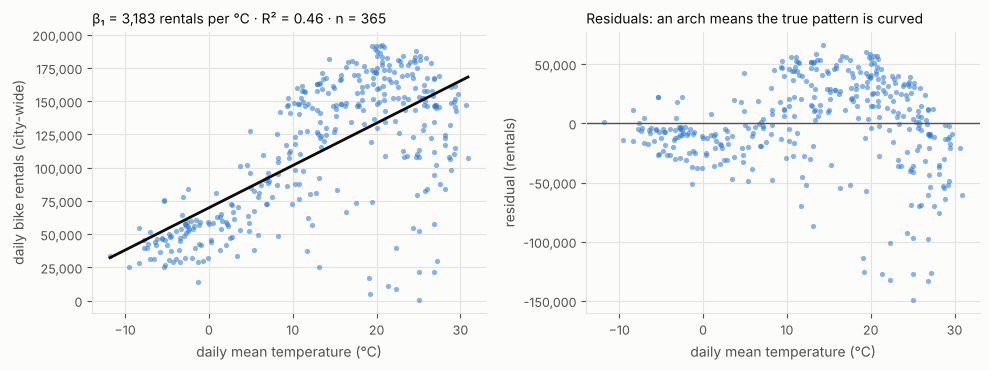

In [22]:
plot_q1(q1_data, q1);

### Figure 2 · why the slope is lower than our 5,000-per-°C guess
**Interpretation:** rain days sit far below the line; usage stops rising near 24 °C (27 °C on dry days).

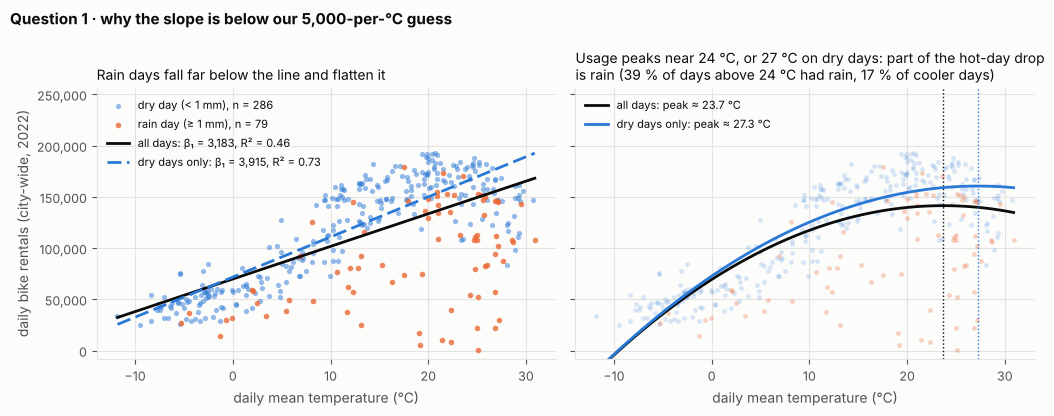

In [23]:
plot_q1_why(q1_data, q1);

## Step 2 · Hourly files → station-day cache, and station zones

In [24]:
sd = load_station_day()
zones = classify_zones()
if zones is not None:
    check_match(sd, zones)

cache: 680,258 station-days from data/station_day_cache.csv.gz


station master: 2,789 stations, 25 districts
subway/park point files not found → zones from station names
zone
U    2489
C     153
L     147
rentals matched to a classified station: 96.6%


### Figure 3 · temperature moves volume, not timing
**Interpretation:** in Oct–Dec daily rentals climb steeply with temperature, while the commuting-hour share stays flat.

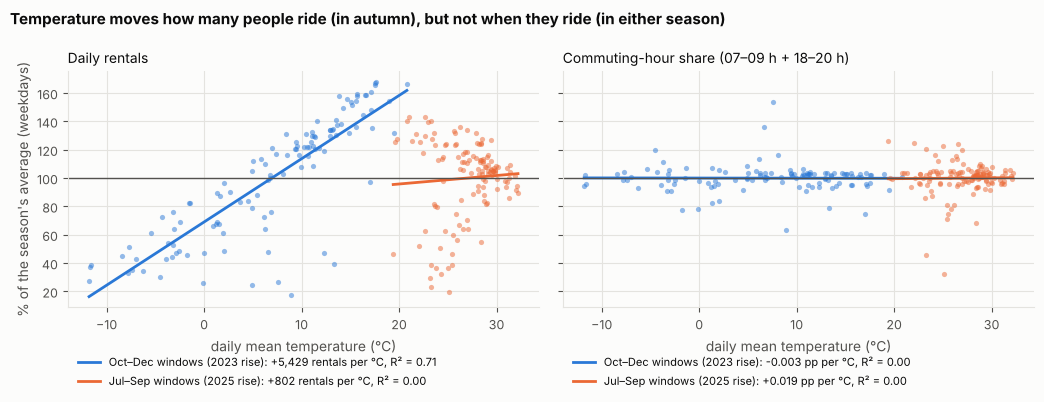

In [25]:
plot_volume_vs_share(sd, weather);

## Questions 2 and 3 · temperature-adjusted fare test
`adj_p_two` is the primary, two-sided p-value (Week 3 canvas); `adj_p` is the one-sided version kept for comparison.

In [26]:
res = run_fare_tests(sd, zones, weather)

 event zone  n_pre  n_post  temp_pre  temp_post  slope_pp_per_C  raw_diff  raw_p  temp_correction  adj_diff  adj_lo  adj_hi  adj_p  adj_p_two  elasticity  degree_equivalent  lag1  post_outside_temp_range_%
     1    C     59      56     6.324      7.577           0.065     0.790  0.111            0.081     0.709  -0.583   2.000  0.139      0.278       0.116             10.901 0.252                     12.500
     1    L     59      56     6.324      7.577          -0.001     0.567  0.205           -0.001     0.569  -0.793   1.930  0.204      0.409       0.097            579.148 0.234                     12.500
     2    C     62      65    27.055     26.806           0.051    -0.805  0.861           -0.013    -0.792  -2.256   0.671  0.857      0.286      -0.423            -15.645 0.133                     10.769
     2    L     62      65    27.055     26.806          -0.025    -0.617  0.809            0.006    -0.623  -2.018   0.771  0.811      0.378      -0.367            -25.020 0.2

### Other test families on the same comparison
* `p_tost` — **equivalence test** (two one-sided tests): a small p means the change is *inside* ±3 pp. This is the test that can support a 'no meaningful effect' claim; a non-significant t-test alone cannot.
* `p_F_var`, `p_levene` — **F-test of variances** and its outlier-robust version (Levene / Brown–Forsythe). They decide whether the equal-variance t-test is safe; we use Welch either way.
* `p_mw_two` — **Mann–Whitney U**, the rank version of the t-test (no normality assumption).
* `p_chi2_day`, `p_fisher_day` — **χ² test on days**: is a day more likely to be a 'high-share' day (above the pre-window median) after the rise?
* `p_chi2_rentals`, `cramers_v_rentals` — **χ² on individual rentals**. Shown only to make the Week 3 point: with ~800,000 rentals treated as independent, a 0.1 pp difference is 'significant'; Cramér's V shows the effect is ~0.
* `mde_80` — smallest change we could detect with 80 % power: below 3 pp, so a null result is informative.

In [27]:
extras = fare_test_extras(sd, zones, weather)

 event zone    diff  p_two  p_tost  var_ratio  p_F_var  p_levene  p_mw_two  p_mw_one  sd_daily  mde_80  days_high_pre  days_high_post  n_pre  n_post  chi2_day  p_chi2_day  p_fisher_day  chi2_rentals  p_chi2_rentals  cramers_v_rentals  n_rentals
     1    C  0.7089 0.2785  0.0003     2.4258   0.0010    0.2008    0.0843    0.0422    3.4670  1.8277             29              36     59      56    2.0970      0.1476        0.1325       16.2394          0.0001             0.0045     799983
     1    L  0.5686 0.4085  0.0003     3.6624   0.0000    0.1232    0.5625    0.2812    3.6413  1.9196             29              30     59      56    0.0825      0.7739        0.7102        0.3612          0.5478             0.0008     579894
     2    C -0.7924 0.2856  0.0017     2.2295   0.0019    0.5677    0.7121    0.6457    4.1792  2.0946             31              34     62      65    0.0068      0.9343        0.8598       21.3234          0.0000             0.0047     955465
     2    L -0.6232 

### Figure 4 · the raw daily shares behind the test

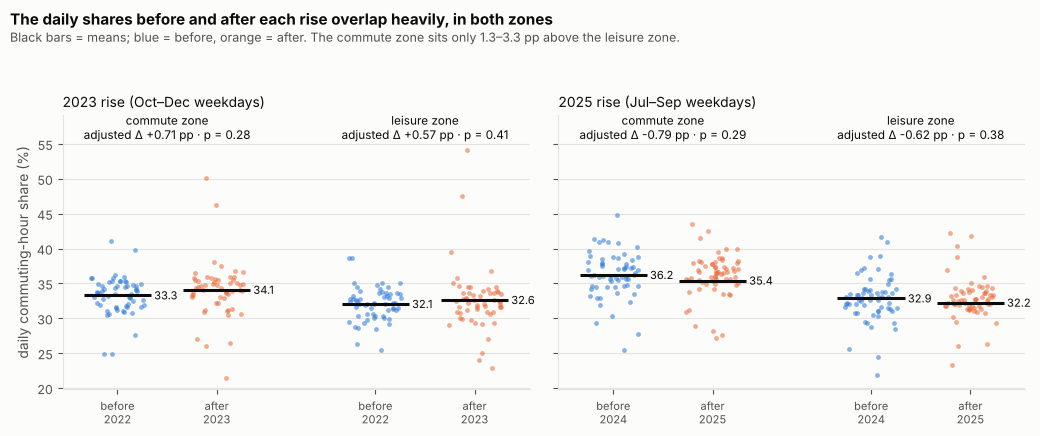

In [28]:
plot_daily_shares(sd, zones, weather, res);

### Figure 5 · the test result for the pitch

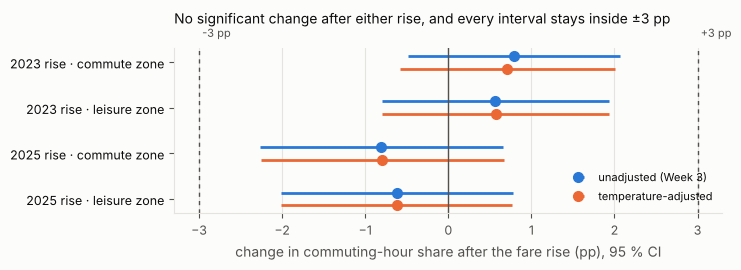

In [29]:
plot_q2(res);

### Dose–response across the two fare rises

In [30]:
if zones is not None:
    dose_response(res)

elasticity, 2023 rise: 0.116 [-0.095, 0.327]
elasticity, 2025 rise: -0.423 [-1.205, 0.358]
intervals overlap: True → both include 0: no detectable response to either rise, and the two cannot be told apart


### Figure 6 · response per 1 % of fare rise

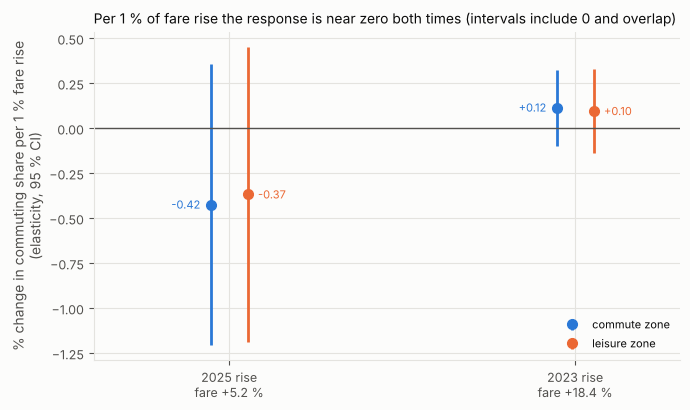

In [31]:
plot_dose_response(res);

### Sensitivity · other day exclusions (commute zone)

In [32]:
sens = sensitivity(sd, zones, weather)

                           variant  event zone  n_pre  n_post  adj_diff  adj_lo  adj_hi  adj_p
     main (strikes + holidays out)      1    C     59      56     0.709  -0.583   2.000  0.139
     main (strikes + holidays out)      2    C     62      65    -0.792  -2.256   0.671  0.857
also drop Chuseok 2024 bridge days      1    C     59      56     0.709  -0.583   2.000  0.139
also drop Chuseok 2024 bridge days      2    C     59      65    -0.635  -2.109   0.839  0.803
     also drop Suneung (exam) days      1    C     58      55     0.436  -0.797   1.669  0.242
     also drop Suneung (exam) days      2    C     62      65    -0.792  -2.256   0.671  0.857
also drop heavy-rain days (≥30 mm)      1    C     59      54     0.797  -0.485   2.080  0.110
also drop heavy-rain days (≥30 mm)      2    C     55      57    -0.407  -1.306   0.491  0.815
        holidays out, strikes kept      1    C     60      58     0.633  -0.628   1.895  0.161
        holidays out, strikes kept      2    C    

## Check · multiple regression share ~ post + temperature + rain (TA-approved)

In [33]:
mlr = mlr_check(sd, zones, weather)

 event zone   n  post_coef  se_HAC     lo    hi  p_one  p_two  temp_coef  rain_coef    R2
     1    C 115      0.847   0.645 -0.417 2.112  0.094  0.189      0.009     -0.037 0.018
     1    L 115      0.661   0.666 -0.644 1.967  0.160  0.321     -0.061     -0.010 0.025
     2    C 127     -0.826   0.637 -2.075 0.422  0.903  0.195     -0.037     -0.068 0.150
     2    L 127     -0.649   0.653 -1.929 0.631  0.840  0.320     -0.090     -0.053 0.099


## Optional · double machine learning (partialling-out)

In [34]:
dml = dml_check(sd, zones, weather)

 event zone   n  theta    se     lo    hi  p_one  p_two
     1    C 115  0.559 0.624 -0.663 1.781  0.185  0.370
     1    L 115  0.328 0.648 -0.942 1.599  0.306  0.612
     2    C 127 -0.703 0.670 -2.016 0.610  0.853  0.294
     2    L 127 -0.570 0.674 -1.890 0.751  0.801  0.398


### Figure 7 · does the answer depend on our choices?

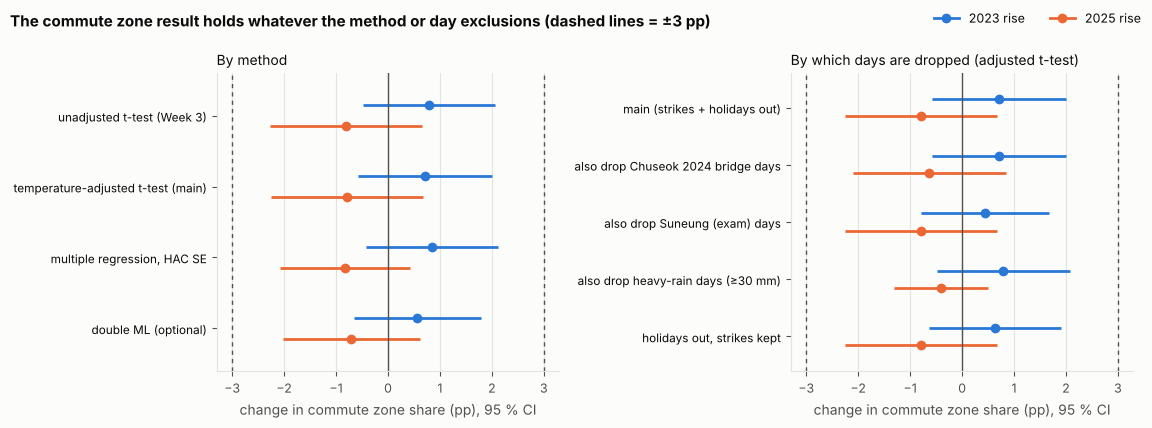

In [35]:
plot_robustness(res, mlr, sens, dml);

## Version 2 · Testing the premise: is 따릉이 mainly a leisure mode?
The conventional wisdom has two parts: a **premise** (따릉이 is mainly leisure, not a real commuting mode) and a **conclusion** (so fares do not change how it is used). Questions 2–3 test the conclusion. Here we turn the premise into three predictions that the data could prove wrong:

* **P1** — if use is leisure-led, rest days (weekends, holidays) should have *more* rides at the same weather. → ANCOVA F-test for day of week, 2022.
* **P2** — if use is leisure-led, park and river stations should be clearly *less* concentrated in commuting hours. → one-way ANOVA F across zones; χ² of zone × hour type with Cramér's V.
* **P3** — if 따릉이 were a real (necessity) commuting mode, commuting-hour rides should be *less* weather-sensitive than other rides. → F-test of the temperature×hour-type and rain×hour-type interactions (cluster-robust by day).

In [36]:
leis = leisure_tests(daily, weather, sd, zones)

P1 day-of-week F = 13.84, p = 3.8e-14; rest days vs workdays at the same weather: -25,726 rentals [-31,340, -20,112], p = 2.7e-19


 event  mean_C  mean_L  mean_U       F    p_F      chi2  p_chi2  cramers_v
     1 33.2891 32.0509 31.9656  5.3954 0.0053  321.1015     0.0     0.0070
     2 36.2096 32.8528 33.9205 16.4888 0.0000 1375.1326     0.0     0.0128
        windows  temp_commute_%  temp_other_%  rain_commute_%  rain_other_%     F   p_F
Oct–Dec windows           5.450         5.460          -4.646        -4.396 0.154 0.858
Jul–Sep windows          -1.050        -0.455          -1.694        -1.285 1.888 0.156
    all windows           4.447         4.522          -1.672        -1.288 1.830 0.163
weekday share of rentals in the 4 commuting hours (city-wide, 4 windows): 33.1 % (4 of 24 hours = 16.7 %)


### Figure 8 · the premise
**Interpretation:** P1 fails — workdays, not weekends, carry the most rides. P2 fails in size — park stations are almost as commute-heavy as anywhere. P3 holds — commuting-hour rides rise and fall with the weather exactly like other rides, which is how an optional, fair-weather mode behaves, not a necessity commute.

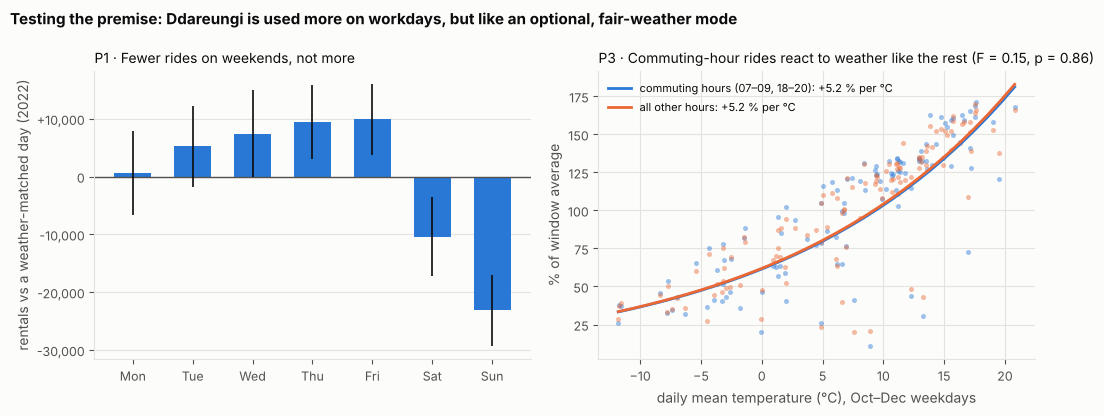

In [37]:
plot_leisure(leis, sd, weather);

## Version 2 · Can we call it causal?
A causal effect compares what happened with what *would* have happened without the fare rise. We never see the second, so each design uses a stand-in and needs an assumption:

| Design | Stand-in for 'no fare rise' | Assumption we check |
|---|---|---|
| Before–after, same dates a year earlier | the commute zone one year before | no other change between years (weakest) |
| Difference-in-differences | the leisure zone / all other stations on the same days | parallel trends: the gap would have stayed the same |
| Station fixed effects | each station against itself | as above, at station level |
| Permutation placebo | 2,000 random groups of stations | none — it shows what 'no special effect' looks like |
| Dose–response | the other fare rise | a bigger rise should do more |

In [38]:
did, gaps = did_tests(sd, zones, weather)

 event control    did     lo     hi     p  F_interaction  p_F_interaction  gap_slope_pre_per30d  gap_slope_change_per30d  p_gap_slope_change  chow_F  p_chow
     1       L  0.223 -0.335  0.782 0.434          0.058            0.811                -0.625                   -0.133               0.647   1.718   0.184
     1       U  0.119 -0.184  0.422 0.441          0.019            0.891                   NaN                      NaN                 NaN     NaN     NaN
     2       L -0.188 -0.743  0.367 0.507          0.037            0.847                 0.197                   -0.341               0.203   0.583   0.560
     2       U -0.430 -0.836 -0.024 0.038          0.201            0.654                   NaN                      NaN                 NaN     NaN     NaN


### Figure 9 · the gap between zones, both years on the same calendar
**Interpretation:** the gap follows the same seasonal path in both years (slope test p > 0.2) and does not jump after the rise; the DiD estimate is about ±0.2 pp.

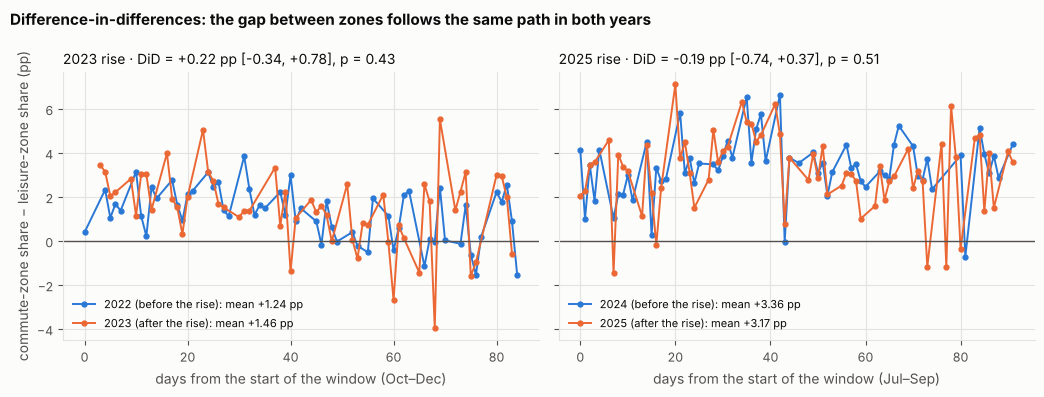

In [39]:
plot_did_gap(gaps, did);

### Station fixed-effects DiD (each station compared with itself, weighted by rentals, SE clustered by station)

In [40]:
fe = did_station_fe(sd, zones, weather)

 event    did     lo    hi     p  stations_C  stations_L  station_days
     1  0.715 -0.114 1.544 0.091         137         129         30083
     2 -0.568 -1.326 0.189 0.141         138         135         34051


### Permutation placebo (2,000 random groups of unclassified stations)

In [41]:
perm, perm_dist = permutation_placebo(sd, zones)

 event  C_change  L_change  random_mean  random_lo  random_hi  share_random_ge_C  p_perm_two  group_size
     1     0.790     0.567        0.658     -0.203      1.522              0.386       0.760         138
     2    -0.805    -0.617       -0.387     -1.090      0.359              0.877       0.244         142


### Figure 10 · placebo
**Interpretation:** the commute zone sits inside the cloud of random station groups.

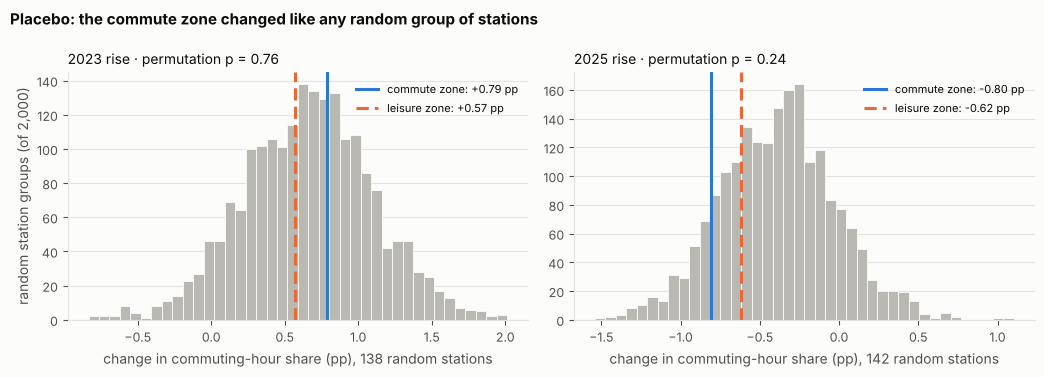

In [42]:
plot_placebo(perm, perm_dist);

### Figure 11 · every causal design on one axis

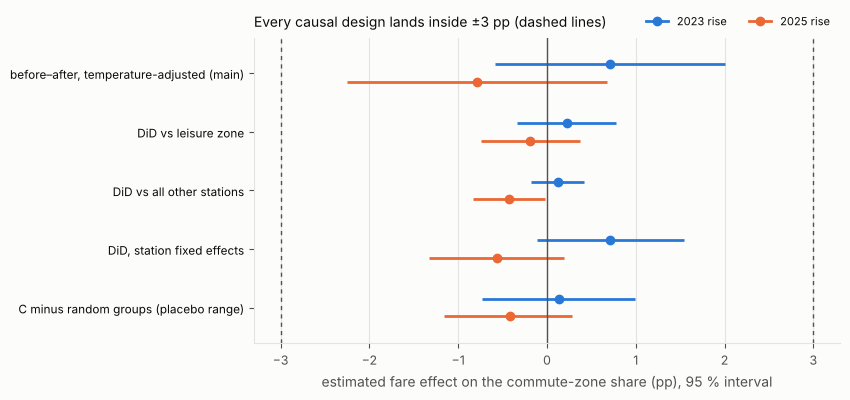

In [43]:
plot_causal_summary(res, did, fe, perm);

## Test catalogue (what each test asks, and its answer)

In [44]:
catalogue = test_catalogue(extras, q1f, leis, did, fe, perm)

                             test                                                   question                        result (2023 / 2025)
              Welch t (two-sided)                         Did the commute-zone share change?                             p = 0.28 / 0.29
         TOST equivalence (±3 pp)                           Is any change smaller than 3 pp?                         p = 0.0003 / 0.0017
      F-test of variances; Levene              Are pre/post spreads equal? (choice of Welch) F p = 0.001 / 0.002; Levene p = 0.20 / 0.57
       Mann–Whitney U (two-sided)                    Same answer without assuming normality?                             p = 0.08 / 0.71
        χ² on days (2×2) + Fisher                     More 'high-share' days after the rise?                             p = 0.15 / 0.93
              χ² on rentals (2×2)                           Why the rental is the wrong unit              p < 0.001, Cramér's V = 0.0045
          Regression F, partial F        

## Week 6 · Professor's feedback: simple vs multiple regression
> *"You've already considered several factors that might affect bike usage, so I'm curious why you chose simple linear regression instead of multiple regression."*

**Why we started simple:** the Week 4 check-in asked for a simple-regression plan, and multiple regression needed approval (the TA approved it as a check in Week 5). **What we do now:** every control from our Week 2 confounder list enters one model, step by step, so each change can be explained. Model 6 is our main model from now on.

* Rain is correlated with heat (summer monsoon), so leaving it out **biases the temperature slope down** (omitted-variable bias).
* Model 5 still left an S-shaped pattern in the residuals across temperature (too low on the coldest days, too high at 0–10 °C), so model 6 adds temperature³. Temperature is centred first; the largest VIF is about 7, below the usual limit of 10.
* Errors are autocorrelated (Durbin–Watson well below 2) and heteroskedastic (Breusch–Pagan p < 0.001) → HAC standard errors.
* Model 8 (month dummies) is a sensitivity check: months absorb part of the temperature variation, so the temperature effect shrinks by a third while held-out fit barely improves.

In [45]:
wx = load_weather_extra()
reg = regression_comparison(daily, weather, wx)

                  model  k    R2  adj_R2  CV_R2      AIC      BIC  temp_effect_at_mean  temp_effect_se_HAC  rain_coef  rest_coef  durbin_watson
               1 simple  1 0.458   0.456  0.451 8736.171 8743.971             3182.906             326.626        NaN        NaN          0.792
          2 + rain (mm)  2 0.666   0.664  0.656 8561.045 8572.744             3646.944             283.879  -1290.889        NaN          0.763
           3 + rest day  3 0.722   0.720  0.714 8495.730 8511.330             3676.227             277.317  -1322.891 -26128.125          0.722
       4 + temperature²  4 0.780   0.778  0.771 8413.047 8432.546             3204.233             235.276  -1282.539 -25725.689          0.982
             5 log rain  4 0.814   0.812  0.807 8351.134 8370.633             3423.576             199.700 -23596.246 -23821.061          1.113
 6 main: + temperature³  5 0.861   0.859  0.856 8246.616 8270.016             5582.247             297.428 -23908.967 -22549.312        

### Figure 12 · what multiple regression adds

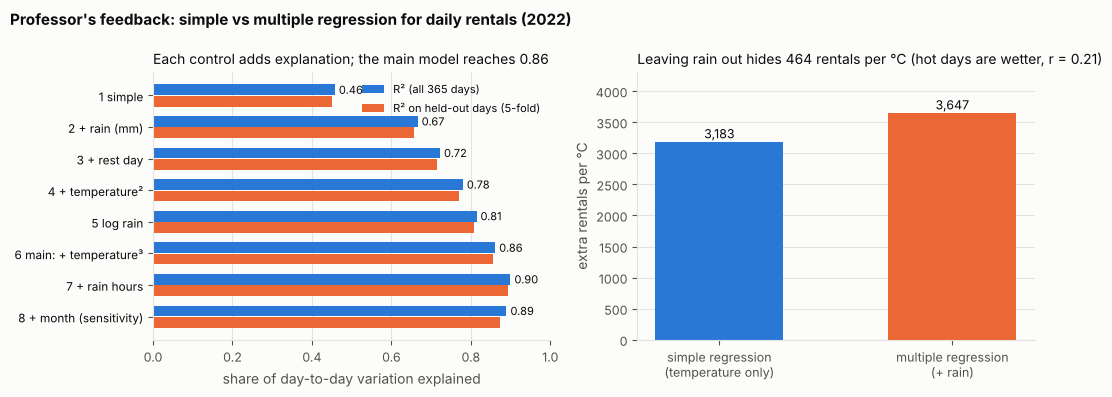

In [46]:
plot_regression_comparison(reg);

### The fare effect with the same controls
Simple regression `share ~ post` is the t-test written as a regression. Adding temperature, rain and weekday explains more of the day-to-day variation (R² 0.01 → 0.12) but barely moves the fare coefficient — the result does not depend on leaving controls out.

In [47]:
fare_reg = fare_regression_comparison(sd, zones, weather)

 event   zone                                        model   post     lo    hi     p    R2  weekday_F  weekday_p
     1      C                         simple: share ~ post  0.790 -0.619 2.200 0.272 0.013        NaN        NaN
     1      C multiple: + temperature + log rain + weekday  0.736 -0.483 1.956 0.237 0.120     11.873      0.000
     1      C                     multiple: + temperature²  0.822 -0.426 2.070 0.197 0.128      9.271      0.000
     1      L                         simple: share ~ post  0.567 -0.897 2.032 0.448 0.006        NaN        NaN
     1      L multiple: + temperature + log rain + weekday  0.491 -0.772 1.754 0.446 0.135     12.778      0.000
     1      L                     multiple: + temperature²  0.590 -0.678 1.857 0.362 0.145      9.079      0.000
     1 C vs L       DiD + temperature + log rain + weekday  0.223 -0.341 0.787 0.438 0.147        NaN        NaN
     2      C                         simple: share ~ post -0.805 -2.056 0.446 0.207 0.009      

## Week 6 · Map C: what a machine-learning model sees
Random forests scored on held-out days (5-fold). Permutation importance = how much held-out R² falls when one input is shuffled. This is the 'ML approach' map of the Three System Maps report. (About 2 minutes.)

In [48]:
ml = ml_maps(daily, weather, wx, sd, zones)

held-out R², daily rentals: {'simple regression': 0.451, 'multiple regression (main)': 0.856, 'random forest, same 3 inputs': 0.841, 'random forest, all 8 inputs': 0.918}
temperature                    1.170
hours of rain                  0.256
month                          0.106
rain (mm)                      0.056
rest day                       0.036
weekday                        0.013
day–night temperature range    0.004
yesterday's rain               0.000
held-out R², commuting-hour share: {'multiple regression': 0.111, 'random forest': 0.464}
day–night temperature range    0.2236
rain (mm)                      0.1757
day of year                    0.1750
hours of rain                  0.1457
weekday                        0.1122
commute zone                   0.0772
temperature                    0.0653
after fare rise                0.0107
leisure zone                   0.0098
summer window                  0.0008


### Figure 13 · ML importance

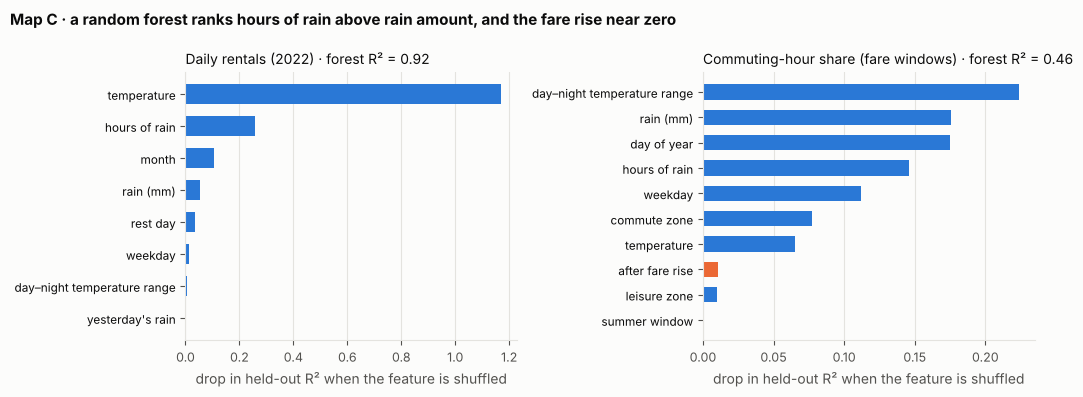

In [49]:
plot_ml_importance(ml);

## Save results

In [50]:
os.makedirs('results', exist_ok=True)
pd.DataFrame([q1]).to_csv('results/q1_temperature.csv', index=False)
for name, df in (('fare_tests', res), ('fare_tests_extra', extras), ('q1_nested_F', q1f), ('sensitivity', sens),
                 ('mlr', mlr), ('dml', dml), ('premise_P2_zones', leis['P2']), ('premise_P3_weather', leis['P3']),
                 ('did', did), ('did_station_fe', fe), ('placebo_permutation', perm), ('test_catalogue', catalogue)):
    df.to_csv(f'results/{name}.csv', index=False)
pd.DataFrame([leis['P1']]).to_csv('results/premise_P1_restdays.csv', index=False)
reg['table'].to_csv('results/q1_model_comparison.csv', index=False)
fare_reg.to_csv('results/fare_model_comparison.csv', index=False)
ml['volume_importance'].rename('importance').to_csv('results/ml_importance_volume.csv')
ml['share_importance'].rename('importance').to_csv('results/ml_importance_share.csv')
leis['P1_by_day'].to_csv('results/premise_P1_by_day.csv')
if zones is not None:
    zones.to_csv('results/station_zones.csv', index=False, encoding='utf-8-sig')
print('saved:', sorted(os.listdir('results')))

saved: ['did.csv', 'did_station_fe.csv', 'dml.csv', 'fare_model_comparison.csv', 'fare_tests.csv', 'fare_tests_extra.csv', 'ml_importance_share.csv', 'ml_importance_volume.csv', 'mlr.csv', 'placebo_permutation.csv', 'premise_P1_by_day.csv', 'premise_P1_restdays.csv', 'premise_P2_zones.csv', 'premise_P3_weather.csv', 'q1_model_comparison.csv', 'q1_nested_F.csv', 'q1_temperature.csv', 'sensitivity.csv', 'station_zones.csv', 'test_catalogue.csv']
